# Gaussian-blob inputs and curriculum benefit

Do small-random-init ReLU MLPs show a **stronger curriculum benefit** when the
inputs are Gaussian blobs (`signal_noise_std > 0`) than when they are the 8
fixed type-5 examples (`std = 0`)? And how does that interact with the **length
of training** and the **number of hidden units**?

This notebook only loads the pickles that `run_blob_experiments.py` produced:

```bash
python run_blob_experiments.py            # full run
python run_blob_experiments.py --quick    # tiny smoke test
```

Curriculum = rule-first ramp of the exception probability; standard = constant
exception probability with the **same mean exposure**. Benefit = curriculum -
standard final exception (peripheral) accuracy.

In [1]:
import json, pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import blob_plotting as bp

RESULTS = Path('results')
def load(name):
    with open(RESULTS / f'{name}.pkl', 'rb') as fh:
        return pickle.load(fh)

metadata = json.load(open(RESULTS / 'metadata.json'))
cfg = metadata['config']
print('device:', metadata['device'], '| seeds/cell:', metadata['seeds_per_cell'])
print('main-sweep width:', cfg['n_hidden'], '| max steps:', cfg['max_steps'],
      '| optimizer:', cfg['optimizer'], '| lr:', cfg['learning_rate'])
print('noise levels:', cfg['noise_levels'])
main = load('main_sweep'); hidden = load('hidden_sweep')

# --- live-training setup for the controllable curve panels ---
import torch, blob_experiments
from blob_task import BlobTask
from blob_experiments import BlobConfig
# DEVICE = torch.device('cuda:1' if (torch.cuda.is_available() and
#                        torch.cuda.device_count() > 1) else
#                       ('cuda:0' if torch.cuda.is_available() else 'cpu'))

DEVICE = 'cpu'
task = BlobTask(DEVICE)
def make_config(**overrides):
    base = dict(metadata['config']); base.update(overrides)
    return BlobConfig(**base)
print('live-train device:', DEVICE)

device: cuda:1 | seeds/cell: 256
main-sweep width: 16 | max steps: 4000 | optimizer: sgd | lr: 0.05
noise levels: [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
live-train device: cpu


## Controls for the learning-curve & loss-curve panels

Set the width, init scale and noise levels the curve panels (sections 3 & 3b)
are drawn from. These train **live** (a few seconds). Re-run this cell after
changing a value, then re-run the curve cells.

In [2]:
CURVE_HIDDEN     = 64                          # hidden units
CURVE_INIT_SCALE = 0.005                       # weight_init_std (small=rich, large=lazy)
CURVE_NOISE      = [0, 0.5, 0.75, 0.85, 1.0, 1.25]   # one panel per noise level
CURVE_STEPS      = 30000
CURVE_SEEDS      = 10                         # lower = faster
ACCURACY_MODE    = 'expected'                    # 'argmax' (hard) or 'expected' (soft, sigmoid confidence)

# curve_data = blob_experiments.compute_curve_data(
#     make_config(), task, noise_levels=CURVE_NOISE, n_hidden=CURVE_HIDDEN,
#     weight_init_std=CURVE_INIT_SCALE, num_steps=CURVE_STEPS, num_seeds=CURVE_SEEDS,
#     accuracy_mode=ACCURACY_MODE)
# print(f'curve_data: width={CURVE_HIDDEN}, init_scale={CURVE_INIT_SCALE}, '
#       f'steps={CURVE_STEPS}, seeds={CURVE_SEEDS}, noise={CURVE_NOISE}')

## 1. Headline: curriculum benefit vs input noise

`std = 0` is the 8 fixed examples; larger `std` makes the classes Gaussian
blobs. Left: final exception accuracy (standard vs curriculum). Right: the
benefit. If the right panel rises above 0 as noise grows, blobs give a stronger
curriculum benefit than fixed examples.

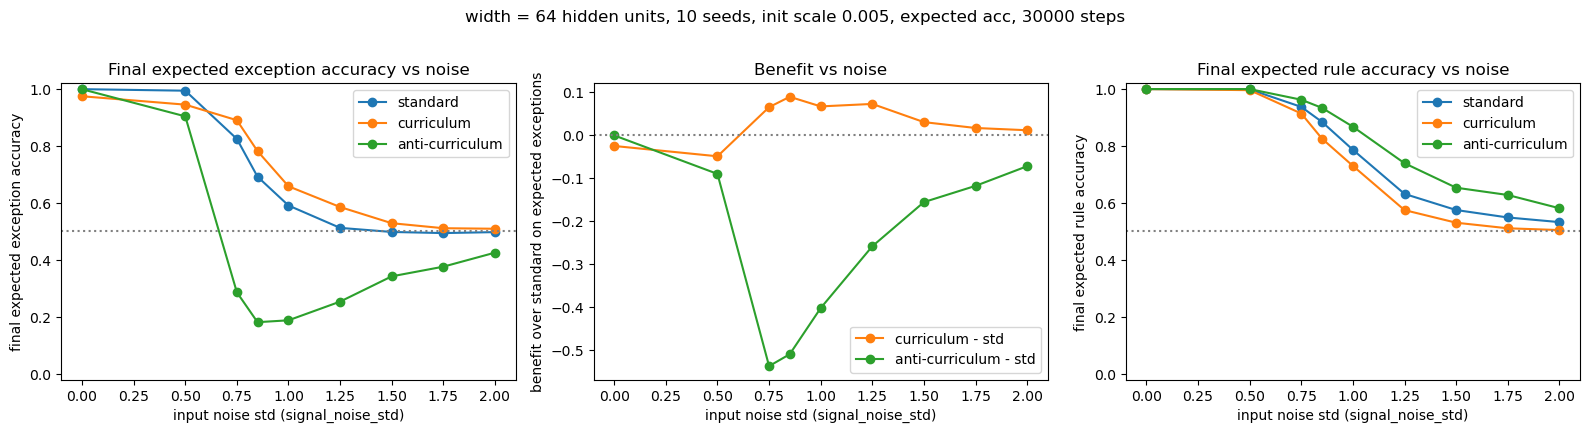

In [3]:
# Uses the top Controls (width / init scale / steps / seeds); only the noise
# list is local -- the benefit plot sweeps the full noise range.
# BENEFIT_NOISE = list(np.round(np.arange(0.0, 2.51, 0.25), 3))
BENEFIT_NOISE      = [0, 0.5, 0.75, 0.85, 1.0, 1.25, 1.5, 1.75, 2.0]   # one panel per noise level
benefit_data = blob_experiments.compute_curve_data(
    make_config(), task, noise_levels=BENEFIT_NOISE,
    n_hidden=CURVE_HIDDEN, weight_init_std=CURVE_INIT_SCALE,
    num_steps=CURVE_STEPS, num_seeds=CURVE_SEEDS, accuracy_mode=ACCURACY_MODE)
bp.plot_benefit_vs_noise(benefit_data)
plt.show()

## 2. Interaction with length of training

Curriculum benefit over (input noise x training steps), from the checkpoints of
the single long run. Red = curriculum helps.

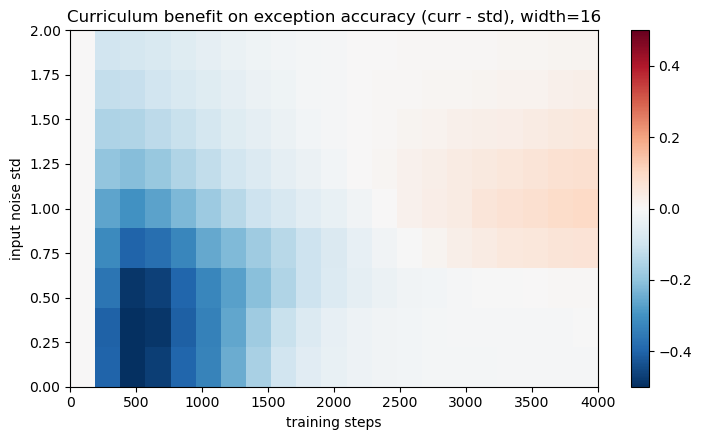

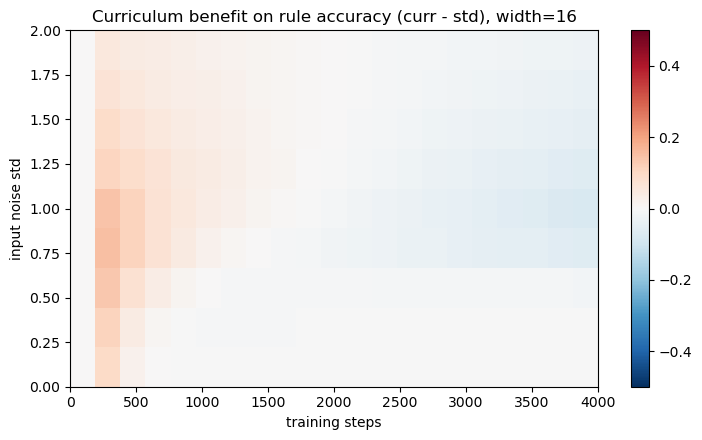

In [37]:
bp.plot_noise_x_steps(main, group='peripheral')   # exception benefit
plt.show()
bp.plot_noise_x_steps(main, group='central')      # rule benefit (blue = curriculum trades away rule)
plt.show()

## 3. Exception learning curves at representative noise levels

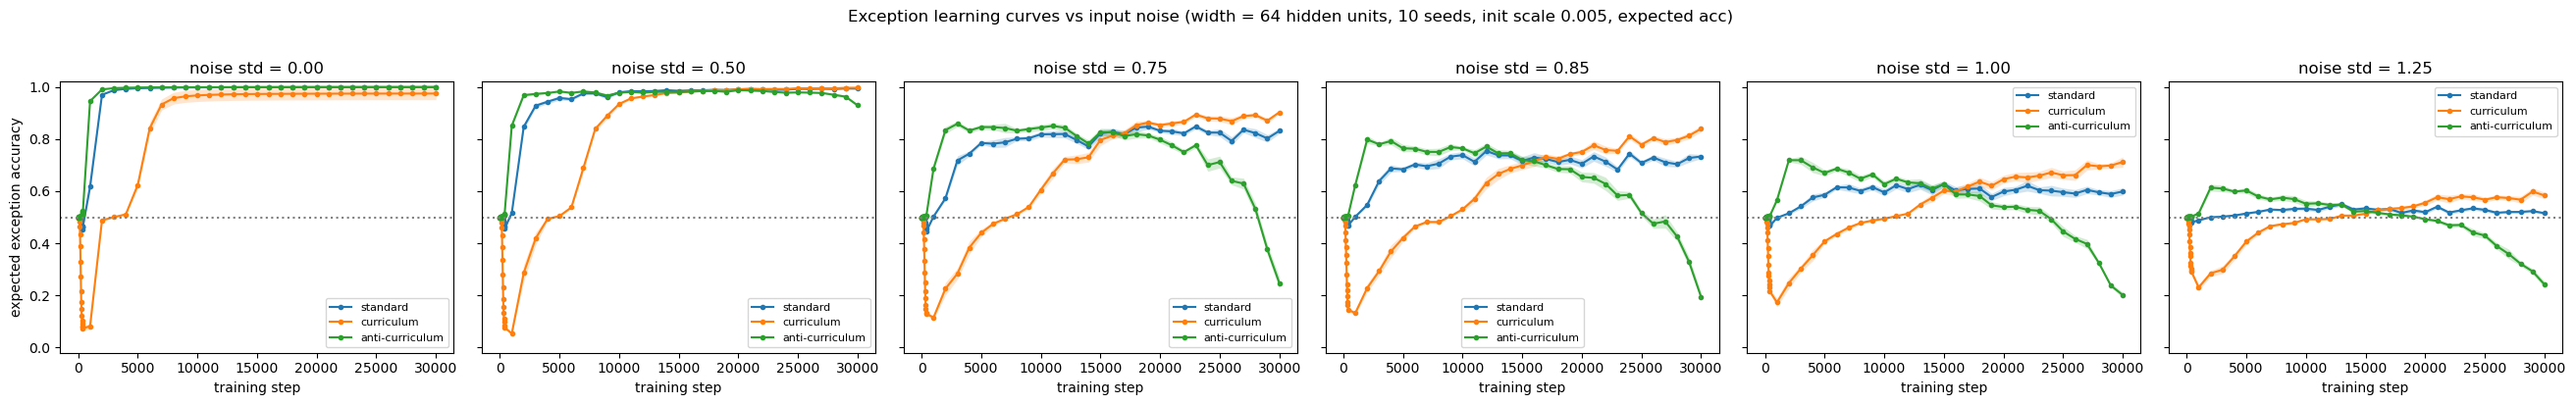

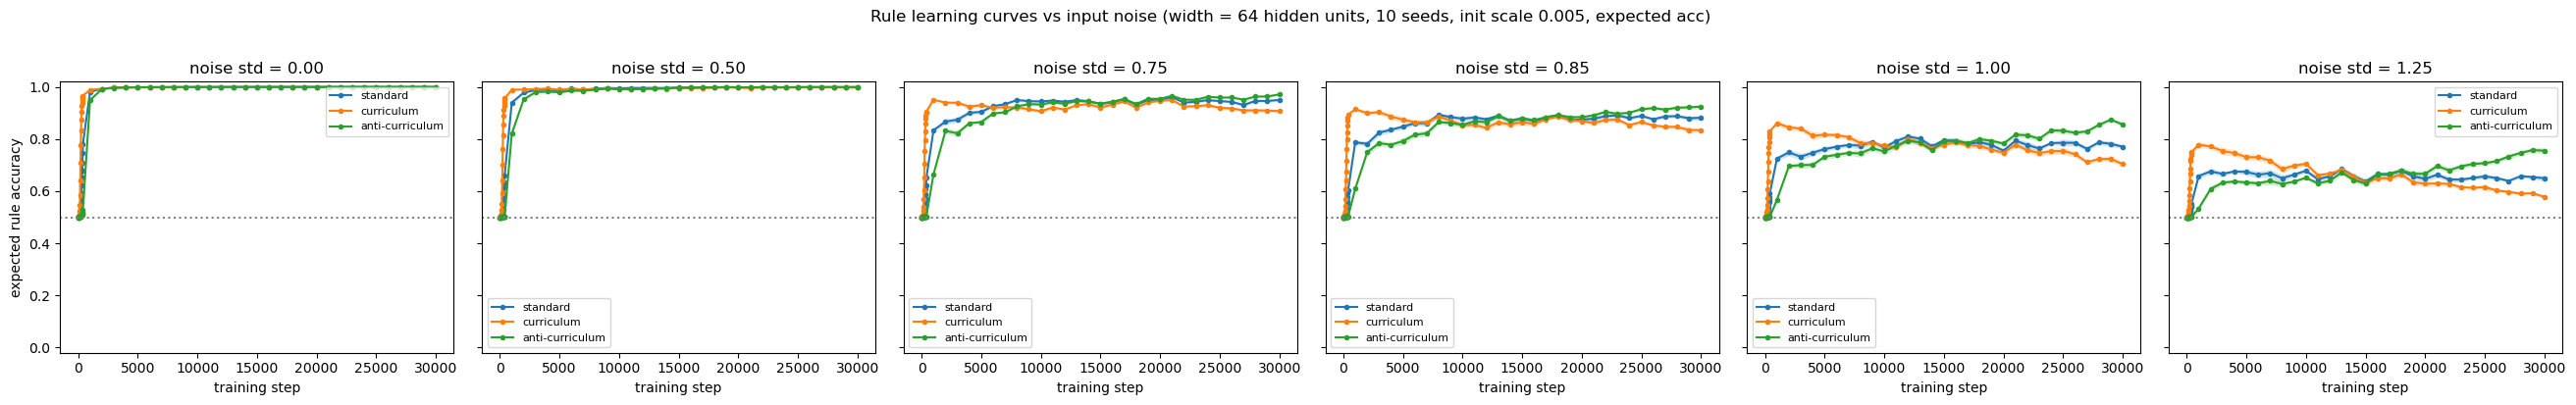

In [5]:
bp.plot_learning_curves(curve_data)   # exception (peripheral) accuracy
plt.show()
bp.plot_rule_learning_curves(curve_data)   # rule (central) accuracy
plt.show()

## 3b. BCE loss: rule vs exception vs combined

Loss on the clean prototypes (the blob centres), at the representative noise
levels. Rows: rule (6 central) loss, exception (2 peripheral) loss, combined
(all 8). The exception-loss row is where standard vs curriculum diverge.

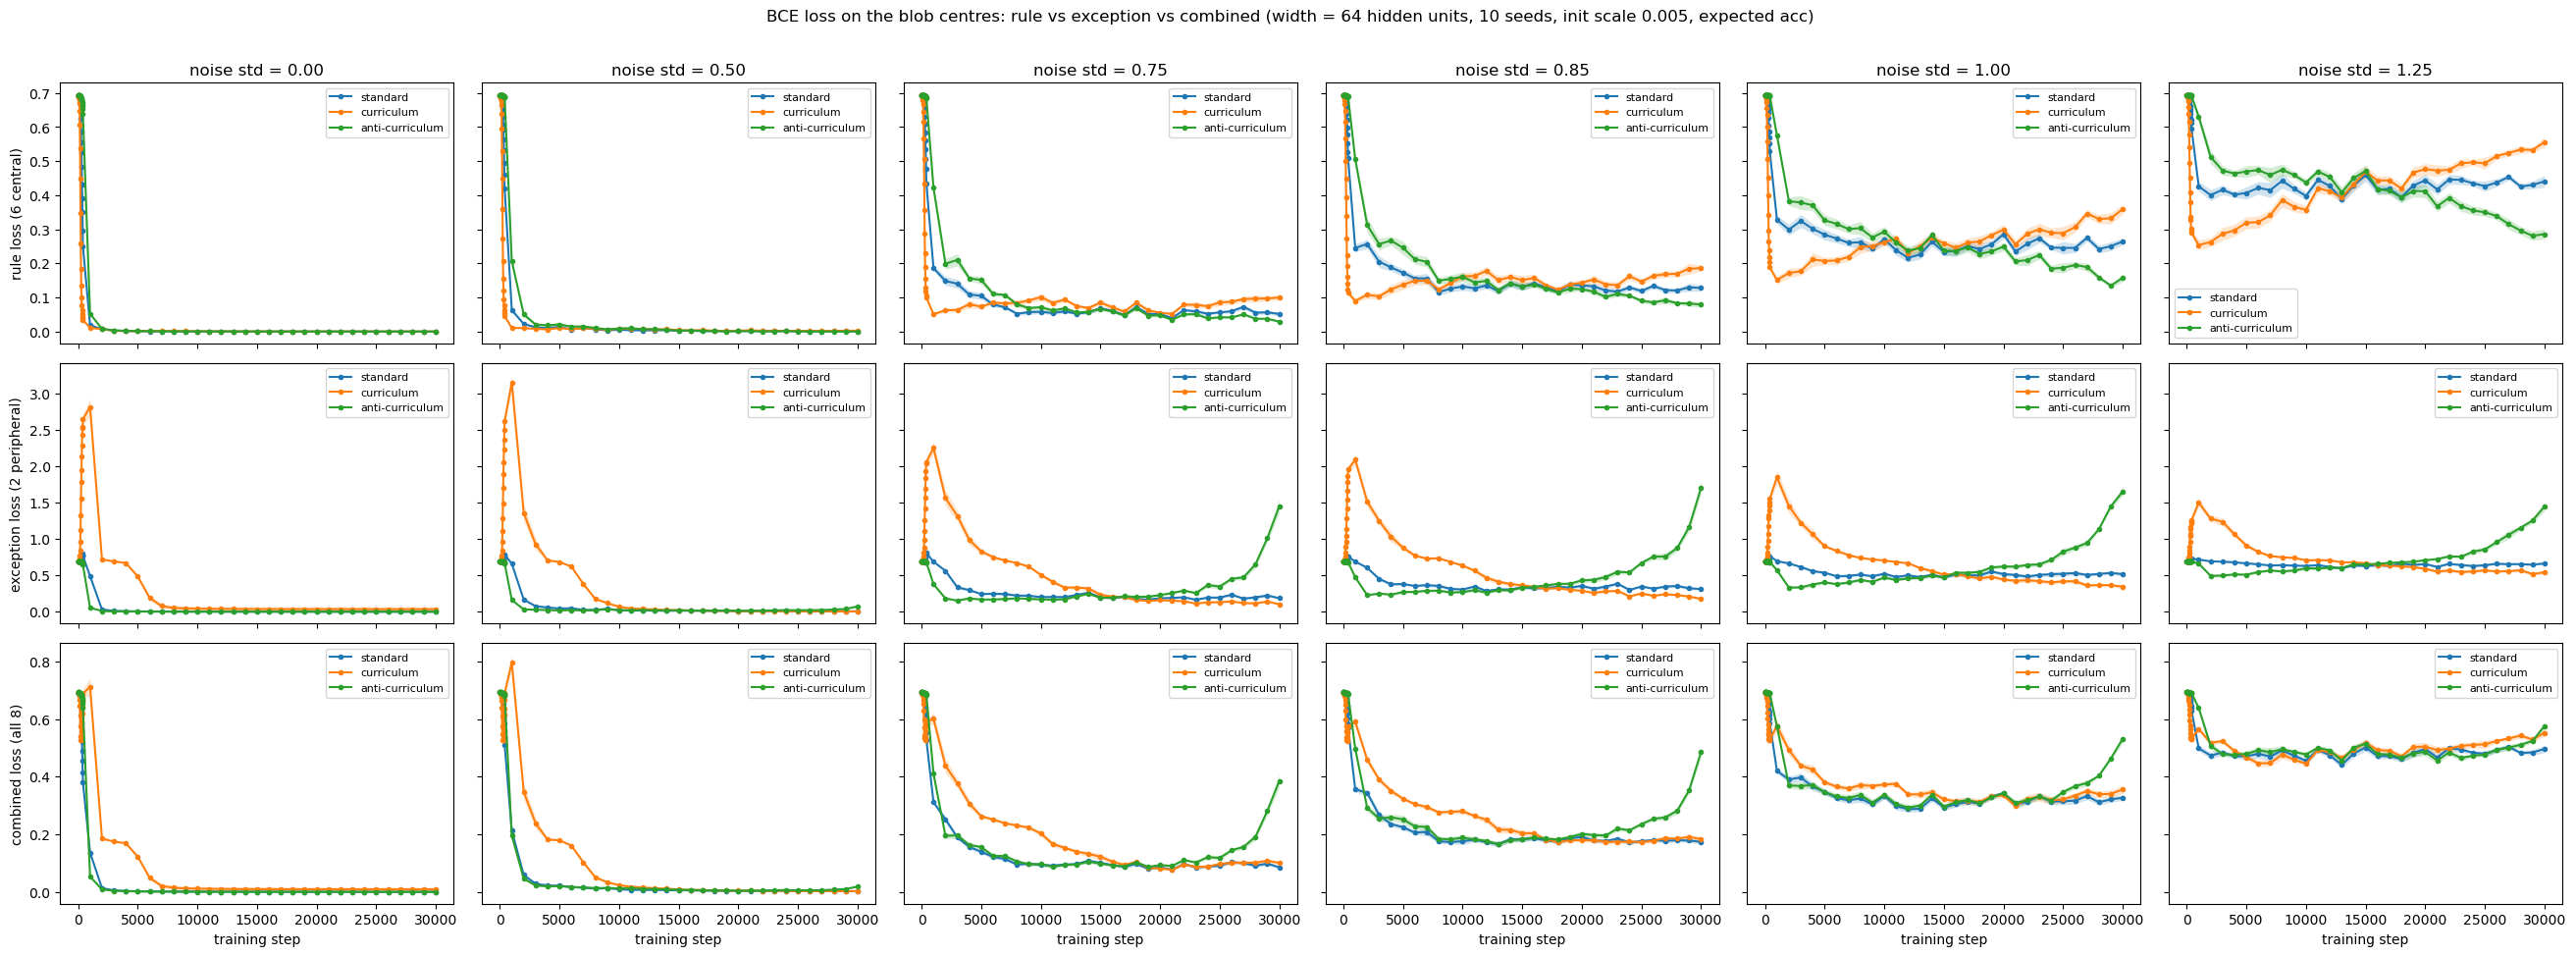

In [6]:
bp.plot_loss_curves(curve_data)
plt.show()

## 3c. Mechanism: representation dimensionality & unit recruitment

Tests the *uncompression* hypothesis. **Participation ratio** is the effective
dimensionality (~1-7) of the 8 centroids' post-ReLU hidden representation
(centered, all 8): higher = less compressed. If curriculum avoids collapsing
onto the rule axis, its PR should stay above standard's, largest where the
accuracy benefit is (intermediate noise). **Active units** = fraction of hidden
units firing on >=1 centroid (the unit-recruitment partner to PR). Uses
`curve_data` from the Controls cell (std vs curr, +/-1 SEM band).

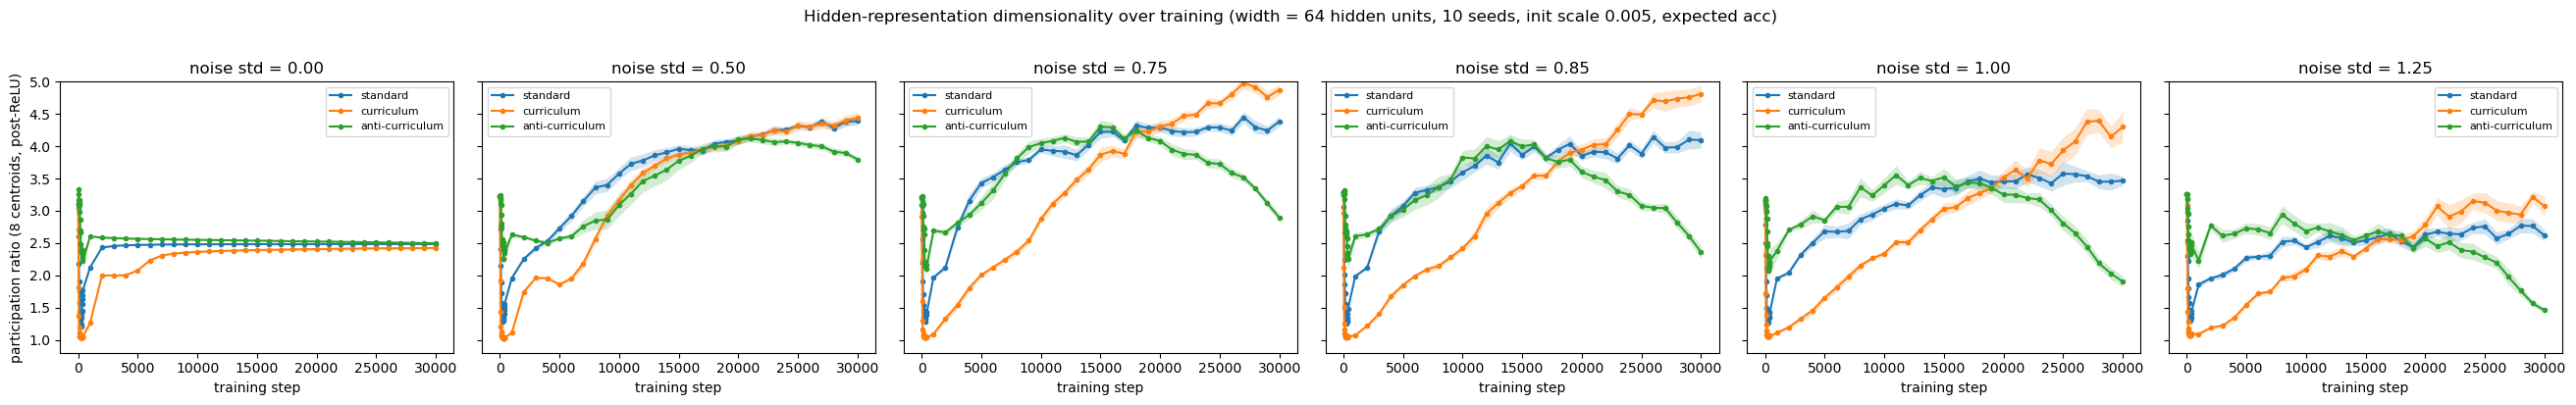

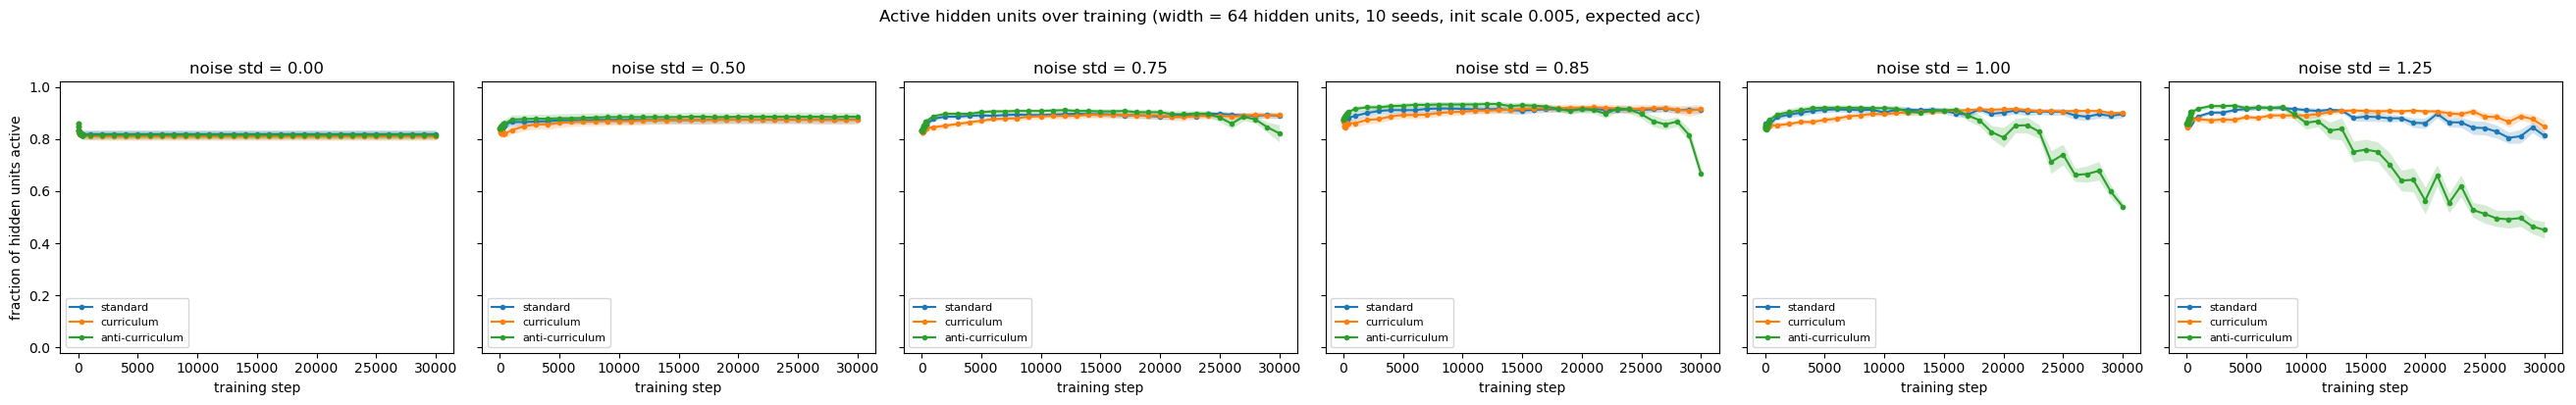

In [7]:
bp.plot_participation_ratio(curve_data)   # effective dimensionality of the 8-centroid rep
plt.show()
bp.plot_active_units(curve_data)          # fraction of hidden units recruited
plt.show()

## 4. Interaction with number of hidden units

Final curriculum benefit over (hidden width x input noise), and the same as
lines (one per width).

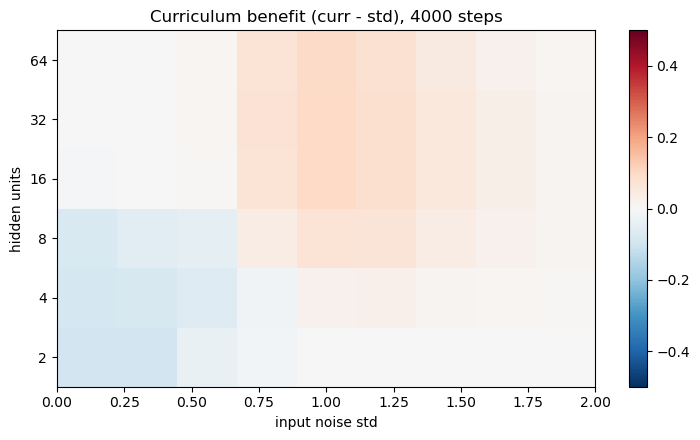

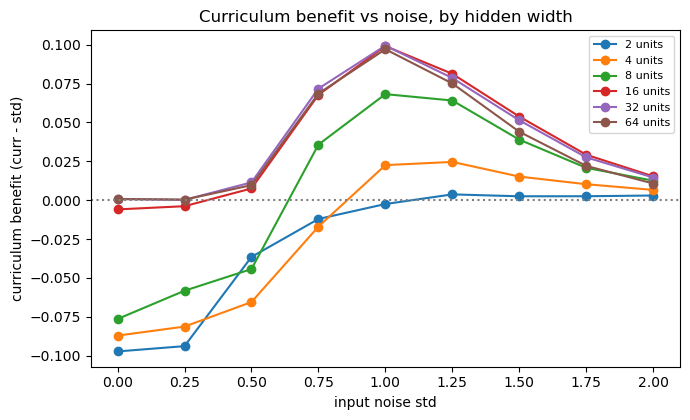

In [8]:
bp.plot_noise_x_hidden(hidden)
plt.show()
bp.plot_hidden_benefit_lines(hidden)
plt.show()

## 5. Initialization scale: rich vs lazy

The hidden-weight init scale (`weight_init_std`) controls the regime: small
= rich / feature-learning, large = lazy (~NTK, features barely move). This
sweeps it against input noise. First row: curriculum benefit on exceptions
and on the rule (blue on the rule = curriculum trades rule for exceptions).
Second row: raw final exception accuracy for standard vs curriculum, to see
the rich/lazy transition directly.

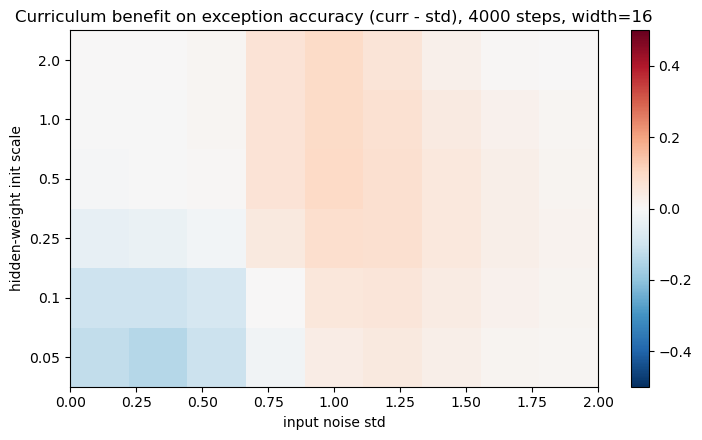

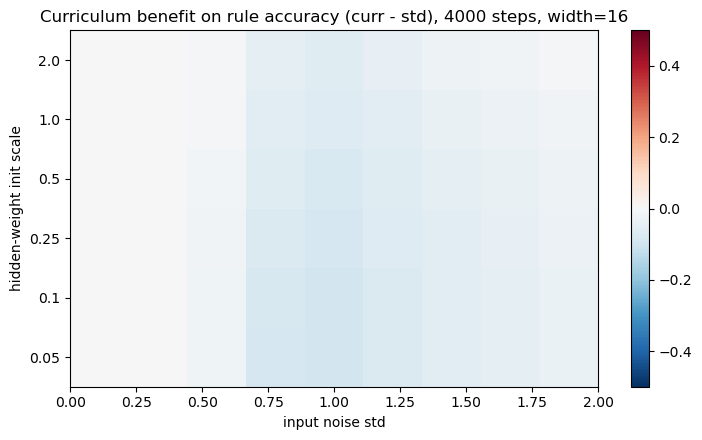

In [9]:
init_scale = load('init_scale_sweep')
bp.plot_init_scale_x_noise(init_scale, group='peripheral')  # exception benefit
plt.show()
bp.plot_init_scale_x_noise(init_scale, group='central')     # rule benefit
plt.show()

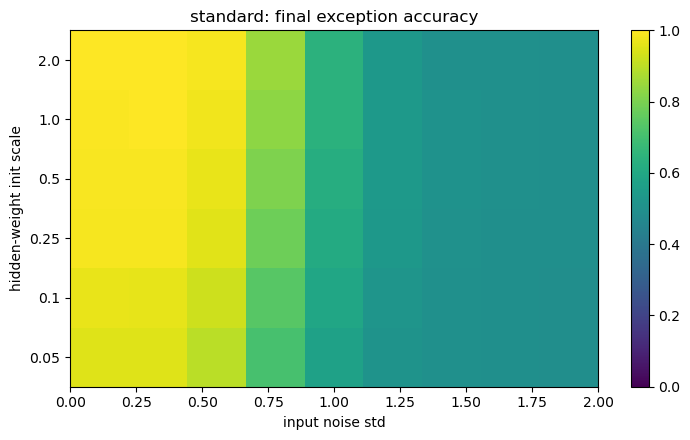

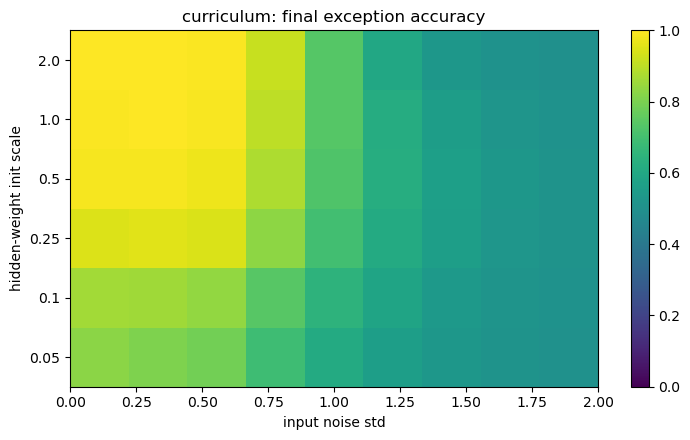

In [10]:
bp.plot_init_scale_accuracy(init_scale, 'standard', 'peripheral')
plt.show()
bp.plot_init_scale_accuracy(init_scale, 'curriculum', 'peripheral')
plt.show()

## Figure 2 (paper): neural networks compress; curriculum uncompresses

Single noise level, rich init, three conditions, with hidden-rep snapshots for
the PCA panel. Uses `make_config()` so params match the rest of the notebook.
The drawing lives in `blob_figures.py` (`plot_figure2`) -- edit it for tighter
control of layout/colours; `FIG_*` below control the data.

In [7]:
# FIG_NOISE  = 1.75
FIG_NOISE  = 1.0
FIG_HIDDEN = 64
FIG_INIT   = 0.005      # weight_init_std (rich)
# FIG_STEPS  = 20000
FIG_STEPS  = 30000
FIG_SEEDS  = 50        # more = tighter SEM bands (slower)
FIG_SNAPS  = [300, FIG_STEPS // 2, FIG_STEPS]   # PCA snapshot steps
# accuracy_mode = 'argmax'   # 'argmax' (hard) or 'expected' (soft, sigmoid confidence)
accuracy_mode = 'expected'   # 'argmax' (hard) or 'expected' (soft, sigmoid confidence)

fig2_data = blob_experiments.compute_curve_data(
    make_config(), task, noise_levels=[FIG_NOISE], n_hidden=FIG_HIDDEN,
    weight_init_std=FIG_INIT, num_steps=FIG_STEPS, num_seeds=FIG_SEEDS,
    accuracy_mode=accuracy_mode, record_rep_steps=FIG_SNAPS)
print('fig2_data ready; snapshots', fig2_data['snapshots'])

fig2_data ready; snapshots [300, 15000, 30000]


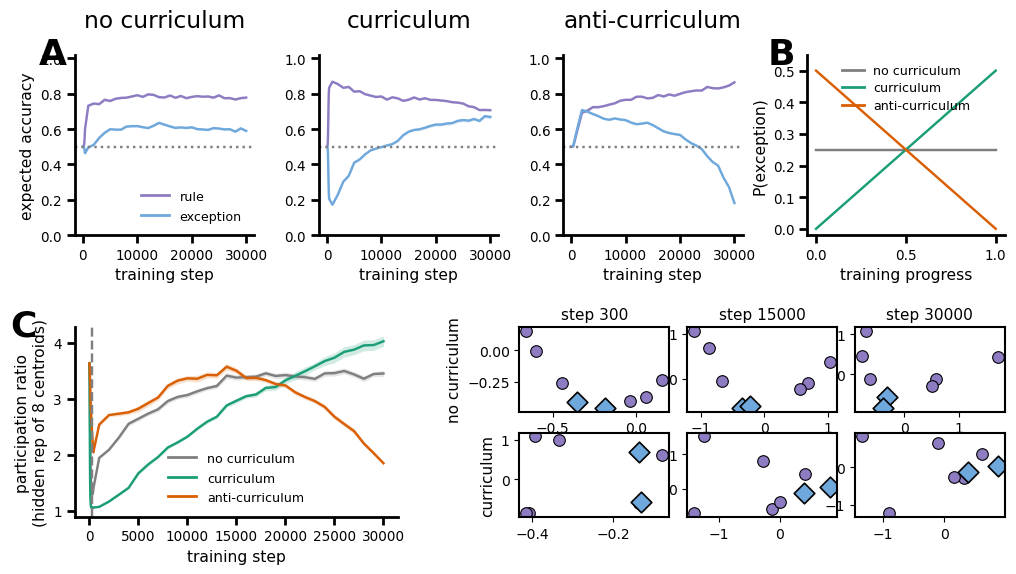

In [8]:
# ===== Figure 2: neural networks compress; curriculum uncompresses =====
import sys, numpy as np, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
sys.path.insert(0, '/mnt/big/jirko/simplicitybias')
from simplicitybias.plot_utils import format_axis

stimColors = {'rule': '#8e7cc3ff', 'exception': '#6fa8dcff'}
condColors = {'standard': '#7f7f7f', 'curriculum': '#1b9e77', 'anti_curriculum': '#d95f02'}
condLabel  = {'standard': 'no curriculum', 'curriculum': 'curriculum', 'anti_curriculum': 'anti-curriculum'}
NOISE_INDEX, PCA_ROWS, FONT_SCALE = 0, ('standard', 'curriculum'), 0.7   # PCA_ROWS: rows of panel D

data = fig2_data
steps, conds, snaps = data['checkpoints'], data['conditions'], data['snapshots']
ni = NOISE_INDEX
is_periph = np.array([False]*6 + [True]*2)

def letter(ax, t):
    ax.text(-0.2, 1.1, t, transform=ax.transAxes, fontsize=26, fontweight='bold', va='top', ha='left')
def band(ax, x, m, s, c, label=None):
    ax.plot(x, m, '-', color=c, label=label)
    if s is not None:
        ax.fill_between(x, m - s, m + s, color=c, alpha=0.2, lw=0)

fig = plt.figure(figsize=(12, 6))
outer = GridSpec(2, 1, height_ratios=[1.0, 1.05], hspace=0.5, figure=fig)

# --- A: accuracy dynamics (rule vs exception), one sub-panel per condition ---
top = GridSpecFromSubplotSpec(1, 4, outer[0], wspace=0.35, width_ratios=[1, 1, 1, 1.1])
acc_lbl = 'expected accuracy' if data.get('accuracy_mode') == 'expected' else 'accuracy'
for j, cond in enumerate(conds):
    ax = fig.add_subplot(top[0, j])
    band(ax, steps, data[f'{cond}_central'][ni], data[f'{cond}_central_sem'][ni], stimColors['rule'], 'rule')
    band(ax, steps, data[f'{cond}_peripheral'][ni], data[f'{cond}_peripheral_sem'][ni], stimColors['exception'], 'exception')
    ax.axhline(0.5, ls=':', c='gray', lw=1.5); ax.set_ylim(0, 1.02)
    ax.set_title(condLabel[cond]); ax.set_xlabel('training step')
    if j == 0:
        ax.set_ylabel(acc_lbl); ax.legend(frameon=False, loc='lower right'); letter(ax, 'A')
    format_axis(ax, line_width_multiplier=1, font_size_multiplier=FONT_SCALE)

# --- B: exposure-schedule schematic ---
ax = fig.add_subplot(top[0, 3]); p = float(data.get('exception_prob', 0.25)); frac = np.linspace(0, 1, 100)
ax.plot(frac, np.full_like(frac, p), color=condColors['standard'], label=condLabel['standard'])
ax.plot(frac, np.clip(2*p*frac, 0, 1), color=condColors['curriculum'], label=condLabel['curriculum'])
ax.plot(frac, np.clip(2*p*(1 - frac), 0, 1), color=condColors['anti_curriculum'], label=condLabel['anti_curriculum'])
ax.set(xlabel='training progress', ylabel='P(exception)', ylim=(-0.02, 0.55))
ax.legend(frameon=False, fontsize=8, loc='upper center'); letter(ax, 'B')
format_axis(ax, line_width_multiplier=1, font_size_multiplier=FONT_SCALE)

# --- bottom: C (participation ratio) + D (PCA snapshots) ---
bot = GridSpecFromSubplotSpec(1, 2, outer[1], wspace=0.3, width_ratios=[1, 1.5])
ax = fig.add_subplot(bot[0, 0])
for cond in conds:
    band(ax, steps, data[f'{cond}_participation_ratio'][ni], data[f'{cond}_participation_ratio_sem'][ni], condColors[cond], condLabel[cond])
ax.set(xlabel='training step', ylabel='participation ratio\n(hidden rep of 8 centroids)')
ax.axvline(FIG_SNAPS[0], ymin=0, ymax=1, ls='--', c='gray', lw=1.5)
ax.legend(frameon=False, loc='best'); letter(ax, 'C')
format_axis(ax, line_width_multiplier=1, font_size_multiplier=FONT_SCALE)

pca_gs = GridSpecFromSubplotSpec(len(PCA_ROWS), len(snaps), bot[0, 1], wspace=0.12, hspace=0.25)
for r, cond in enumerate(PCA_ROWS):
    ci = conds.index(cond)
    ref = data['rep_snapshots'][snaps[-1]][ci, 0]      # (8, H), seed 0; common basis per row
    mean = ref.mean(0, keepdims=True)
    _, _, vt = np.linalg.svd(ref - mean, full_matrices=False); basis = vt[:2].T
    for c, step in enumerate(snaps):
        ax = fig.add_subplot(pca_gs[r, c])
        proj = (data['rep_snapshots'][step][ci, 0] - mean) @ basis
        ax.scatter(proj[~is_periph, 0], proj[~is_periph, 1], s=70, color=stimColors['rule'],
                   edgecolors='k', linewidths=0.8, label='rule' if (r == 0 and c == 0) else None)
        ax.scatter(proj[is_periph, 0], proj[is_periph, 1], s=110, marker='D', color=stimColors['exception'],
                   edgecolors='k', linewidths=1.2, label='exception' if (r == 0 and c == 0) else None)
        # ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(f'step {step}', fontsize=11)
        if c == 0: ax.set_ylabel(condLabel[cond], fontsize=11)
        for sp in ax.spines.values(): sp.set_linewidth(1.5)
        # if r == 0 and c == 0:
        #     ax.legend(frameon=False, fontsize=8, loc='upper left'); letter(ax, 'D')

noise = float(np.asarray(data['noise_levels'])[ni])
# fig.suptitle(f"Neural networks compress; curriculum uncompresses "
#              f"(noise {noise}, width {data['n_hidden']}, init {data.get('weight_init_std', '?')})", fontsize=15, y=1.0)
# fig.savefig('figure2.pdf', bbox_inches='tight'); fig.savefig('figure2.png', dpi=200, bbox_inches='tight')
plt.show()


In [ ]:
# # FIG_NOISE  = 1.75
# FIG_NOISE  = 0.85
# FIG_HIDDEN = 64
# FIG_INIT   = 1      # weight_init_std (rich)
# # FIG_INIT   = 0.005      # weight_init_std (rich)
# FIG_READOUT_INIT = 0.005
# FIG_STEPS  = 2000
# FIG_SEEDS  = 500         # more = tighter SEM bands (slower)
# FIG_SNAPS  = [300, FIG_STEPS // 2, FIG_STEPS]   # PCA snapshot steps
# accuracy_mode = 'expected'   # 'argmax' (hard) or 'expected' (soft, sigmoid confidence)
# FIG_RANK   = 1       # None = full-rank init (unchanged); 1 or 2 = exactly-rank-r
# FIG_TEMP   = 1        # <- output sigmoid temperature: sigmoid(logit / T). 1 = as before

# fig_rank_data = blob_experiments.compute_curve_data(
#     make_config(), task, noise_levels=[FIG_NOISE], n_hidden=FIG_HIDDEN,
#     weight_init_std=FIG_INIT, num_steps=FIG_STEPS, num_seeds=FIG_SEEDS,
#     accuracy_mode=accuracy_mode, record_rep_steps=FIG_SNAPS,
#     rank=FIG_RANK, output_temperature=FIG_TEMP, readout_init_std=FIG_READOUT_INIT)
# print('fig_rank_data ready; snapshots', fig_rank_data['snapshots'], '| rank', fig_rank_data['rank'])


fig_rank_data ready; snapshots [300, 10000, 20000] | rank 1


In [11]:
# FIG_NOISE  = 1.75
FIG_NOISE  = 0.85
FIG_HIDDEN = 64
FIG_INIT   = 1      # weight_init_std (rich)
# FIG_INIT   = 0.005      # weight_init_std (rich)
FIG_READOUT_INIT = 0.005
FIG_STEPS  = 3000
FIG_SEEDS  = 10         # more = tighter SEM bands (slower)
FIG_SNAPS  = [300, FIG_STEPS // 2, FIG_STEPS]   # PCA snapshot steps
accuracy_mode = 'expected'   # 'argmax' (hard) or 'expected' (soft, sigmoid confidence)
FIG_RANK   = 1       # None = full-rank init (unchanged); 1 or 2 = exactly-rank-r
FIG_TEMP   = 1        # <- output sigmoid temperature: sigmoid(logit / T). 1 = as before

fig_rank_data = blob_experiments.compute_curve_data(
    make_config(), task, noise_levels=[FIG_NOISE], n_hidden=FIG_HIDDEN,
    weight_init_std=FIG_INIT, num_steps=FIG_STEPS, num_seeds=FIG_SEEDS,
    accuracy_mode=accuracy_mode, record_rep_steps=FIG_SNAPS,
    rank=FIG_RANK, output_temperature=FIG_TEMP, readout_init_std=FIG_READOUT_INIT)
print('fig_rank_data ready; snapshots', fig_rank_data['snapshots'], '| rank', fig_rank_data['rank'])

fig_rank_data ready; snapshots [300, 1500, 3000] | rank 1


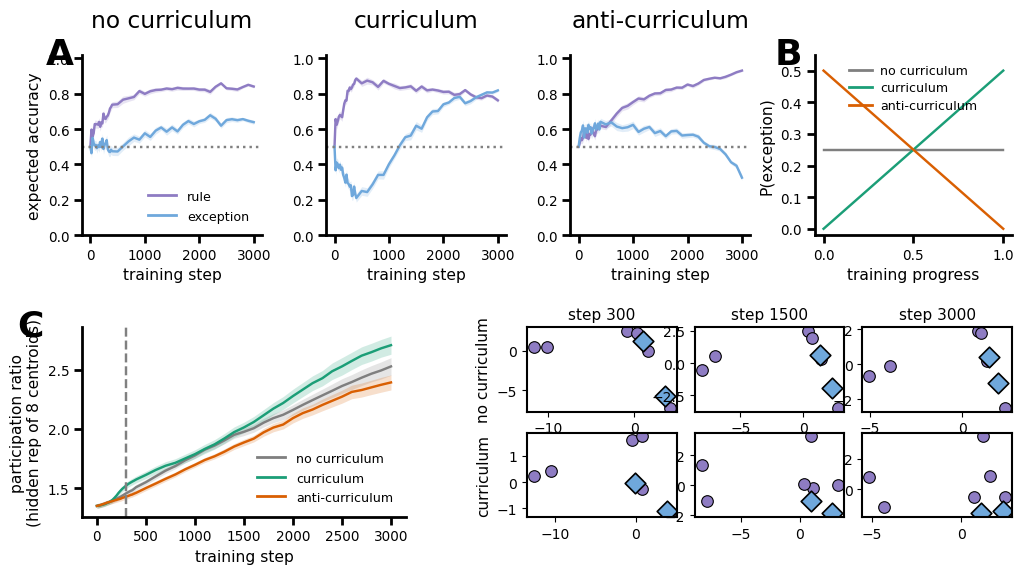

In [65]:
# ===== Figure 2: neural networks compress; curriculum uncompresses =====
import sys, numpy as np, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
sys.path.insert(0, '/mnt/big/jirko/simplicitybias')
from simplicitybias.plot_utils import format_axis

stimColors = {'rule': '#8e7cc3ff', 'exception': '#6fa8dcff'}
condColors = {'standard': '#7f7f7f', 'curriculum': '#1b9e77', 'anti_curriculum': '#d95f02'}
condLabel  = {'standard': 'no curriculum', 'curriculum': 'curriculum', 'anti_curriculum': 'anti-curriculum'}
NOISE_INDEX, PCA_ROWS, FONT_SCALE = 0, ('standard', 'curriculum'), 0.7   # PCA_ROWS: rows of panel D

data = fig_rank_data
steps, conds, snaps = data['checkpoints'], data['conditions'], data['snapshots']
ni = NOISE_INDEX
is_periph = np.array([False]*6 + [True]*2)

def letter(ax, t):
    ax.text(-0.2, 1.1, t, transform=ax.transAxes, fontsize=26, fontweight='bold', va='top', ha='left')
def band(ax, x, m, s, c, label=None):
    ax.plot(x, m, '-', color=c, label=label)
    if s is not None:
        ax.fill_between(x, m - s, m + s, color=c, alpha=0.2, lw=0)

fig = plt.figure(figsize=(12, 6))
outer = GridSpec(2, 1, height_ratios=[1.0, 1.05], hspace=0.5, figure=fig)

# --- A: accuracy dynamics (rule vs exception), one sub-panel per condition ---
top = GridSpecFromSubplotSpec(1, 4, outer[0], wspace=0.35, width_ratios=[1, 1, 1, 1.1])
acc_lbl = 'expected accuracy' if data.get('accuracy_mode') == 'expected' else 'accuracy'
for j, cond in enumerate(conds):
    ax = fig.add_subplot(top[0, j])
    band(ax, steps, data[f'{cond}_central'][ni], data[f'{cond}_central_sem'][ni], stimColors['rule'], 'rule')
    band(ax, steps, data[f'{cond}_peripheral'][ni], data[f'{cond}_peripheral_sem'][ni], stimColors['exception'], 'exception')
    ax.axhline(0.5, ls=':', c='gray', lw=1.5); ax.set_ylim(0, 1.02)
    ax.set_title(condLabel[cond]); ax.set_xlabel('training step')
    if j == 0:
        ax.set_ylabel(acc_lbl); ax.legend(frameon=False, loc='lower right'); letter(ax, 'A')
    format_axis(ax, line_width_multiplier=1, font_size_multiplier=FONT_SCALE)

# --- B: exposure-schedule schematic ---
ax = fig.add_subplot(top[0, 3]); p = float(data.get('exception_prob', 0.25)); frac = np.linspace(0, 1, 100)
ax.plot(frac, np.full_like(frac, p), color=condColors['standard'], label=condLabel['standard'])
ax.plot(frac, np.clip(2*p*frac, 0, 1), color=condColors['curriculum'], label=condLabel['curriculum'])
ax.plot(frac, np.clip(2*p*(1 - frac), 0, 1), color=condColors['anti_curriculum'], label=condLabel['anti_curriculum'])
ax.set(xlabel='training progress', ylabel='P(exception)', ylim=(-0.02, 0.55))
ax.legend(frameon=False, fontsize=8, loc='upper center'); letter(ax, 'B')
format_axis(ax, line_width_multiplier=1, font_size_multiplier=FONT_SCALE)

# --- bottom: C (participation ratio) + D (PCA snapshots) ---
bot = GridSpecFromSubplotSpec(1, 2, outer[1], wspace=0.3, width_ratios=[1, 1.5])
ax = fig.add_subplot(bot[0, 0])
for cond in conds:
    band(ax, steps, data[f'{cond}_participation_ratio'][ni], data[f'{cond}_participation_ratio_sem'][ni], condColors[cond], condLabel[cond])
ax.set(xlabel='training step', ylabel='participation ratio\n(hidden rep of 8 centroids)')
ax.axvline(FIG_SNAPS[0], ymin=0, ymax=1, ls='--', c='gray', lw=1.5)
ax.legend(frameon=False, loc='best'); letter(ax, 'C')
format_axis(ax, line_width_multiplier=1, font_size_multiplier=FONT_SCALE)

pca_gs = GridSpecFromSubplotSpec(len(PCA_ROWS), len(snaps), bot[0, 1], wspace=0.12, hspace=0.25)
for r, cond in enumerate(PCA_ROWS):
    ci = conds.index(cond)
    ref = data['rep_snapshots'][snaps[-1]][ci, 0]      # (8, H), seed 0; common basis per row
    mean = ref.mean(0, keepdims=True)
    _, _, vt = np.linalg.svd(ref - mean, full_matrices=False); basis = vt[:2].T
    for c, step in enumerate(snaps):
        ax = fig.add_subplot(pca_gs[r, c])
        proj = (data['rep_snapshots'][step][ci, 0] - mean) @ basis
        ax.scatter(proj[~is_periph, 0], proj[~is_periph, 1], s=70, color=stimColors['rule'],
                   edgecolors='k', linewidths=0.8, label='rule' if (r == 0 and c == 0) else None)
        ax.scatter(proj[is_periph, 0], proj[is_periph, 1], s=110, marker='D', color=stimColors['exception'],
                   edgecolors='k', linewidths=1.2, label='exception' if (r == 0 and c == 0) else None)
        # ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(f'step {step}', fontsize=11)
        if c == 0: ax.set_ylabel(condLabel[cond], fontsize=11)
        for sp in ax.spines.values(): sp.set_linewidth(1.5)
        # if r == 0 and c == 0:
        #     ax.legend(frameon=False, fontsize=8, loc='upper left'); letter(ax, 'D')

noise = float(np.asarray(data['noise_levels'])[ni])
# fig.suptitle(f"Neural networks compress; curriculum uncompresses "
#              f"(noise {noise}, width {data['n_hidden']}, init {data.get('weight_init_std', '?')})", fontsize=15, y=1.0)
# fig.savefig('figure2.pdf', bbox_inches='tight'); fig.savefig('figure2.png', dpi=200, bbox_inches='tight')
plt.show()


T=1500 done
T=2000 done
T=2500 done
T=3000 done
T=5000 done
T=10000 done


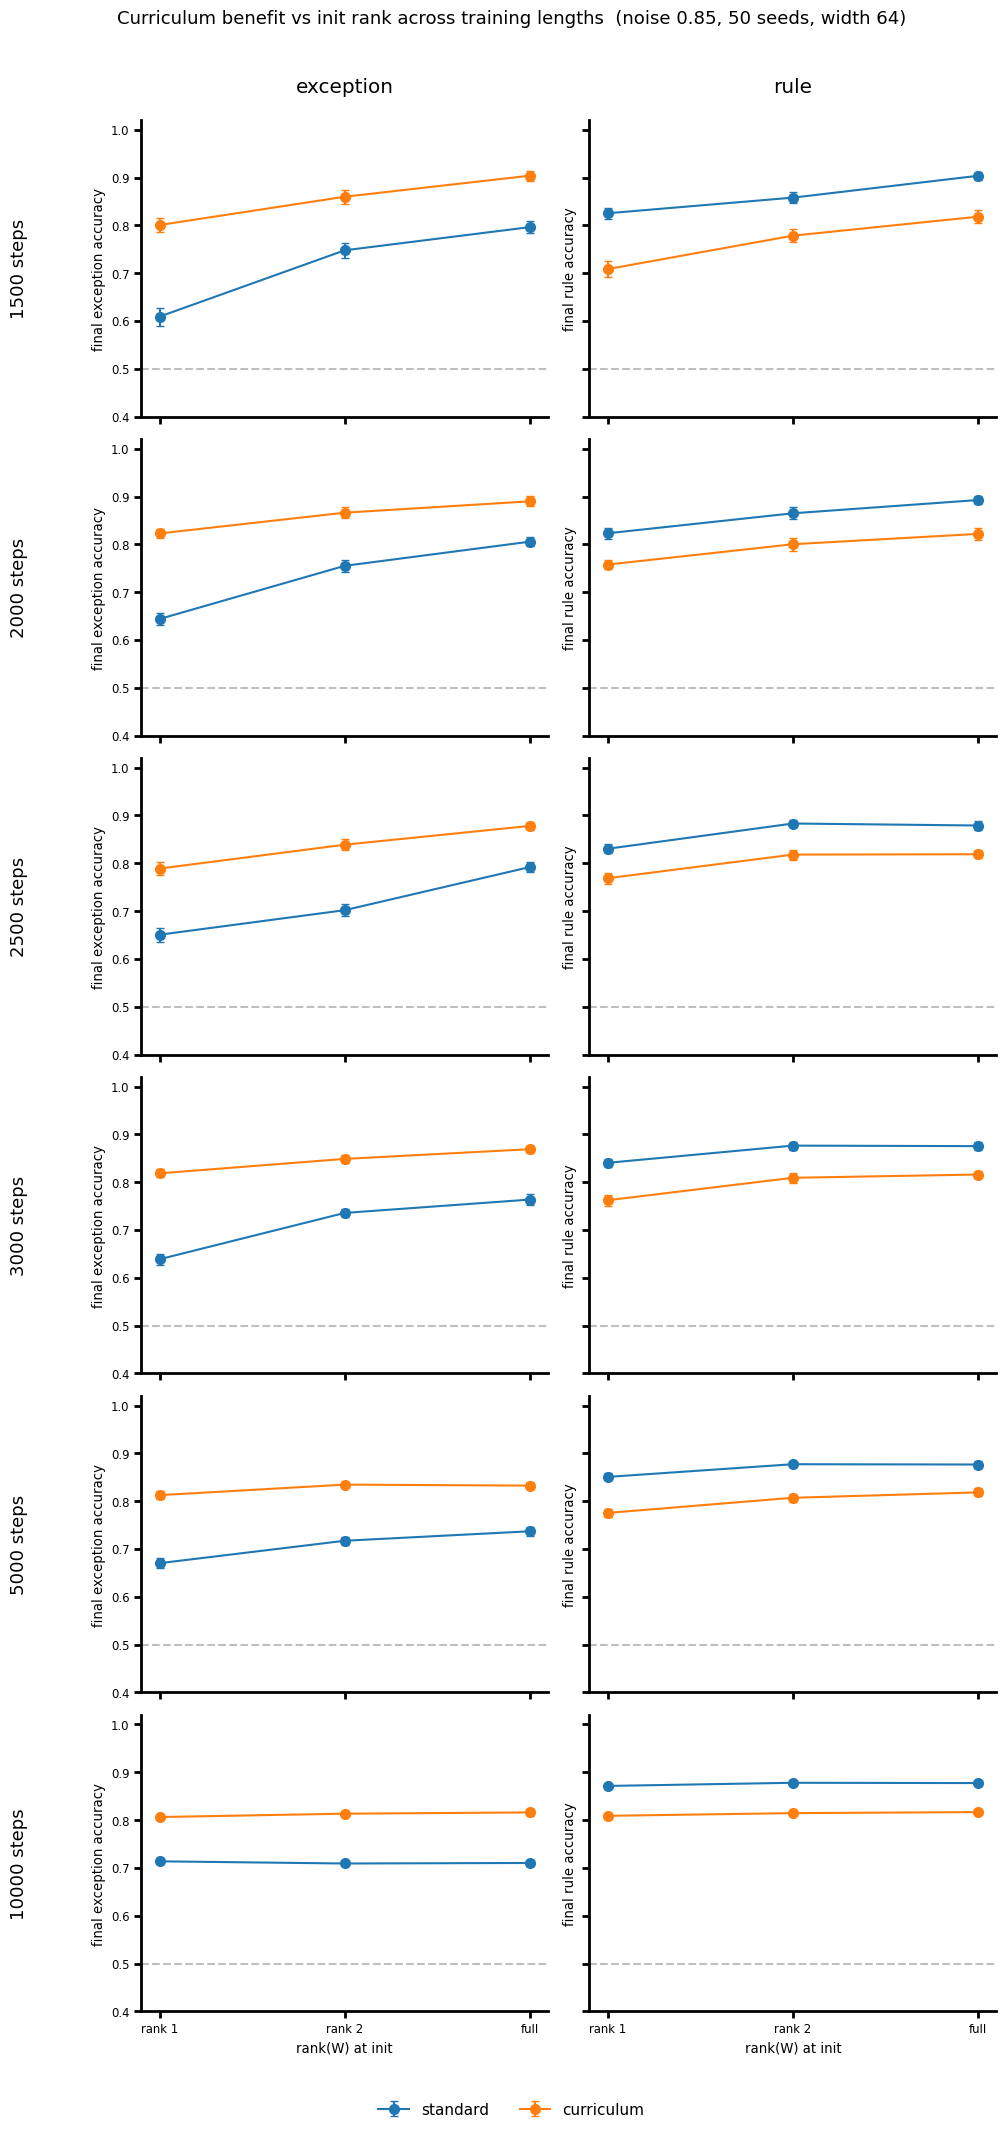


  steps  rank     std    curr  benefit
   1500     1   0.609   0.801   +0.192
   1500     2   0.748   0.860   +0.112
   1500  None   0.796   0.904   +0.108
   2000     1   0.644   0.823   +0.179
   2000     2   0.755   0.866   +0.111
   2000  None   0.806   0.890   +0.084
   2500     1   0.651   0.789   +0.138
   2500     2   0.702   0.839   +0.137
   2500  None   0.792   0.878   +0.086
   3000     1   0.639   0.819   +0.180
   3000     2   0.736   0.849   +0.113
   3000  None   0.764   0.869   +0.105
   5000     1   0.670   0.813   +0.142
   5000     2   0.717   0.835   +0.117
   5000  None   0.737   0.833   +0.096
  10000     1   0.714   0.806   +0.093
  10000     2   0.709   0.813   +0.104
  10000  None   0.710   0.816   +0.106


In [66]:
# --- Curriculum benefit vs rank(W), across training lengths ---
STEP_VALUES = [1500, 2000, 2500, 3000,  5000, 10000]   # rows; each needs its OWN run (see note)

rank_step_runs = {}
for T in STEP_VALUES:
    for r in RANK_VALUES:
        rank_step_runs[(T, r)] = blob_experiments.compute_curve_data(
            make_config(), task, noise_levels=[FIG_NOISE], n_hidden=FIG_HIDDEN,
            weight_init_std=FIG_INIT, num_steps=T, num_seeds=FIG_SEEDS,
            checkpoints=[T],                      # only the endpoint is needed
            accuracy_mode=accuracy_mode, rank=r,
            output_temperature=FIG_TEMP, readout_init_std=FIG_READOUT_INIT)
    print(f'T={T} done')

labels = [('rank 1' if r == 1 else 'rank 2' if r == 2 else 'full') for r in RANK_VALUES]
x = np.arange(len(RANK_VALUES))
GROUPS = (('peripheral', 'exception'), ('central', 'rule'))

nrow, ncol = len(STEP_VALUES), len(GROUPS)
fig, axes = plt.subplots(nrow, ncol, figsize=(5.0 * ncol, 3.4 * nrow),
                         sharex=True, sharey=True, squeeze=False)
for ri, T in enumerate(STEP_VALUES):
    for j, (key, name) in enumerate(GROUPS):
        ax = axes[ri][j]
        for cond, col in (('standard', 'C0'), ('curriculum', 'C1')):
            m = [rank_step_runs[(T, r)][f'{cond}_{key}'][0, -1] for r in RANK_VALUES]
            e = [rank_step_runs[(T, r)][f'{cond}_{key}_sem'][0, -1] for r in RANK_VALUES]
            ax.errorbar(x, m, yerr=e, marker='o', ms=7, capsize=3, color=col, label=cond)
        ax.axhline(0.5, ls='--', lw=1, color='gray', alpha=0.5)
        ax.set_xticks(x); ax.set_xticklabels(labels)
        ax.set_ylim(0.4, 1.02)
        ax.set_ylabel(f'final {name} accuracy')
        if ri == nrow - 1:
            ax.set_xlabel('rank(W) at init')
        if ri == 0:
            ax.set_title(name, fontsize=12)
        format_axis(ax, 1, 0.6)
    axes[ri][0].annotate(f'{T} steps', xy=(-0.30, 0.5), xycoords='axes fraction',
                         rotation=90, va='center', ha='center', fontsize=13)

handles, lbls = axes[0][0].get_legend_handles_labels()
fig.legend(handles, lbls, frameon=False, fontsize=11, ncol=2,
           loc='lower center', bbox_to_anchor=(0.5, -0.03))
fig.suptitle(f'Curriculum benefit vs init rank across training lengths  '
             f'(noise {FIG_NOISE}, {FIG_SEEDS} seeds, width {FIG_HIDDEN})',
             y=1.01, fontsize=13)
plt.tight_layout(); plt.show()

print(f"\n{'steps':>7} {'rank':>5} {'std':>7} {'curr':>7} {'benefit':>8}")
for T in STEP_VALUES:
    for r in RANK_VALUES:
        d = rank_step_runs[(T, r)]
        s_, c_ = d['standard_peripheral'][0, -1], d['curriculum_peripheral'][0, -1]
        print(f'{T:7d} {str(r):>5} {s_:7.3f} {c_:7.3f} {c_ - s_:+8.3f}')


Init sanity (H=64, d=3, init_std=0.005):
  rank=   1 -> emp rank=1, PR(W)=1.00, ||W||_F=0.0693
  rank=   2 -> emp rank=2, PR(W)=2.00, ||W||_F=0.0693
  rank=None -> emp rank=3, PR(W)=2.85, ||W||_F=0.0693
rank=   1 done
rank=   2 done
rank=None done


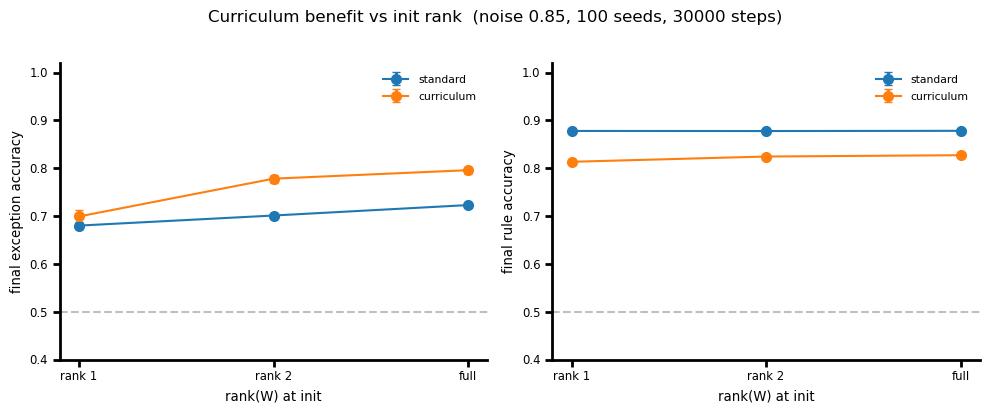

rank=   1: std=0.680  curr=0.700  benefit=+0.019
rank=   2: std=0.702  curr=0.778  benefit=+0.077
rank=None: std=0.723  curr=0.796  benefit=+0.073


In [41]:
# --- Curriculum benefit vs rank(W) at init (fixed training length) ---
import torch as _t
from blob_training import random_init_state

RANK_VALUES = [1, 2, None]      # None = full-rank Gaussian init (PR(W) ~ 2.85)

# sanity: rank / PR(W) / ||W||_F of the init (mirrors the collaborator's check)
print(f'Init sanity (H={FIG_HIDDEN}, d=3, init_std={FIG_INIT}):')
for r in RANK_VALUES:
    W = random_init_state(200, FIG_HIDDEN, FIG_INIT, make_config().small_init_std,
                          False, _t.Generator(device=DEVICE).manual_seed(0),
                          DEVICE, rank=r)['W0']
    sv = _t.linalg.svdvals(W); pr = ((sv**2).sum(-1)**2 / (sv**4).sum(-1)).mean()
    print(f'  rank={str(r):>4} -> emp rank={int((sv[0] > 1e-6).sum())}, '
          f'PR(W)={pr:.2f}, ||W||_F={W.norm(dim=(-2, -1)).mean():.4f}')

rank_runs = {}
for r in RANK_VALUES:
    rank_runs[r] = blob_experiments.compute_curve_data(
        make_config(), task, noise_levels=[FIG_NOISE], n_hidden=FIG_HIDDEN,
        weight_init_std=FIG_INIT, num_steps=FIG_STEPS, num_seeds=FIG_SEEDS,
        accuracy_mode=accuracy_mode, rank=r, output_temperature=FIG_TEMP, readout_init_std=FIG_READOUT_INIT)
    print(f'rank={str(r):>4} done')

# --- Plot: exception + rule accuracy vs rank, standard vs curriculum ---
labels = [('rank 1' if r == 1 else 'rank 2' if r == 2 else 'full') for r in RANK_VALUES]
x = np.arange(len(RANK_VALUES))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for j, (key, name) in enumerate((('peripheral', 'exception'), ('central', 'rule'))):
    for cond, col in (('standard', 'C0'), ('curriculum', 'C1')):
        m = [rank_runs[r][f'{cond}_{key}'][0, -1] for r in RANK_VALUES]
        e = [rank_runs[r][f'{cond}_{key}_sem'][0, -1] for r in RANK_VALUES]
        ax[j].errorbar(x, m, yerr=e, marker='o', ms=7, capsize=3, color=col, label=cond)
    ax[j].axhline(0.5, ls='--', lw=1, color='gray', alpha=0.5)
    ax[j].set_xticks(x); ax[j].set_xticklabels(labels)
    ax[j].set_xlabel('rank(W) at init'); ax[j].set_ylabel(f'final {name} accuracy')
    ax[j].set_ylim(0.4, 1.02); ax[j].legend(frameon=False, fontsize=9)
    format_axis(ax[j], 1, 0.6)
fig.suptitle(f'Curriculum benefit vs init rank  (noise {FIG_NOISE}, '
             f'{FIG_SEEDS} seeds, {FIG_STEPS} steps)', y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

for r in RANK_VALUES:
    d = rank_runs[r]
    ben = d['curriculum_peripheral'][0, -1] - d['standard_peripheral'][0, -1]
    print(f"rank={str(r):>4}: std={d['standard_peripheral'][0, -1]:.3f}  "
          f"curr={d['curriculum_peripheral'][0, -1]:.3f}  benefit={ben:+.3f}")


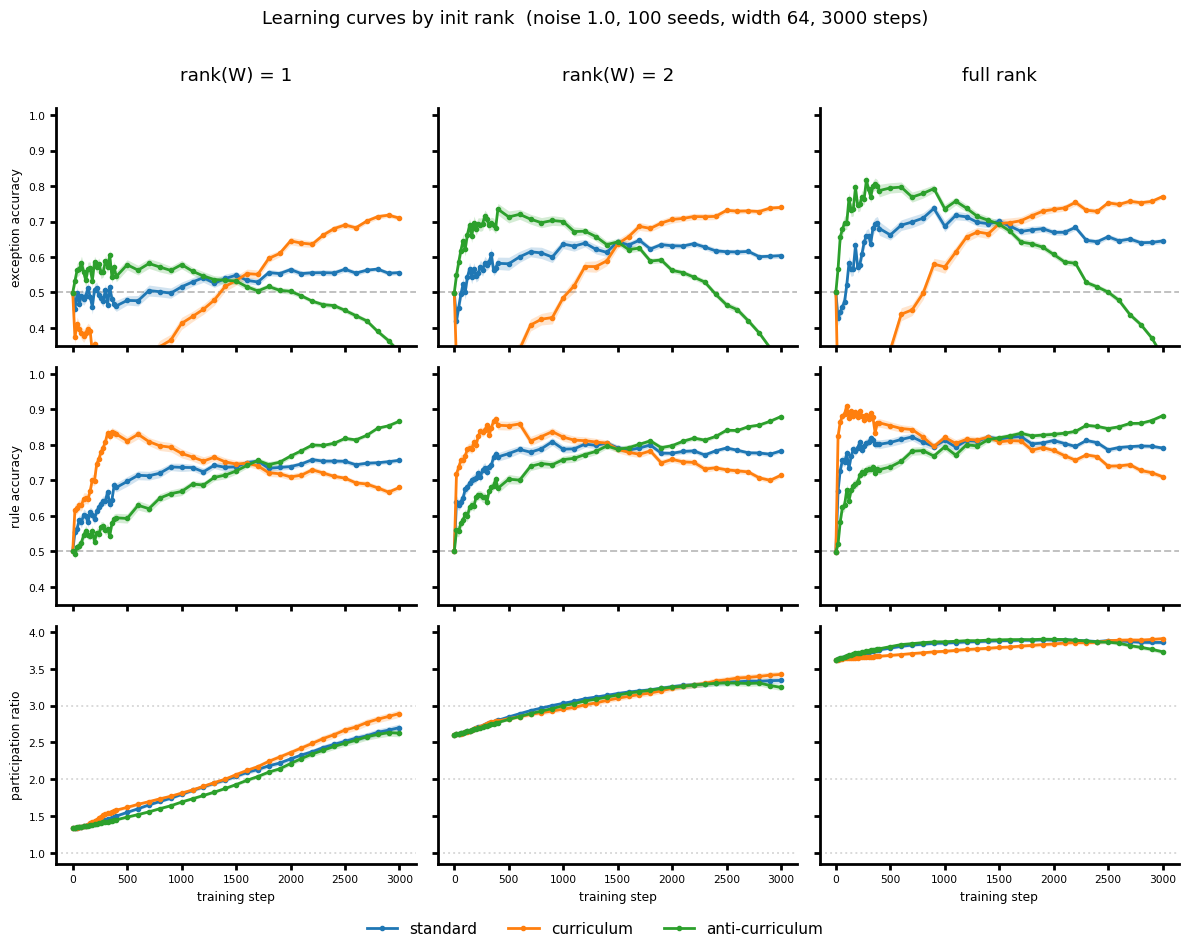

In [27]:
# --- Learning curves per rank(W) at init ---
CURVE_ROWS = [('peripheral',          'exception accuracy',   (0.35, 1.02), 0.5),
              ('central',             'rule accuracy',        (0.35, 1.02), 0.5),
              ('participation_ratio', 'participation ratio',  None,         None)]
LOG_X = False        # True = symlog x-axis (useful for very long runs)

nrow, ncol = len(CURVE_ROWS), len(RANK_VALUES)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.0 * ncol, 3.0 * nrow),
                         sharex=True, sharey='row', squeeze=False)
for ci, r in enumerate(RANK_VALUES):
    d = rank_runs[r]
    steps = d['checkpoints']
    for ri, (key, ylabel, ylim, ref) in enumerate(CURVE_ROWS):
        ax = axes[ri][ci]
        for cond in bp._conditions_present(d, key):
            bp._line_with_band(ax, steps, d, cond, key, 0)   # 0 = the single noise level
        if ref is not None:
            ax.axhline(ref, ls='--', lw=1.0, color='gray', alpha=0.5, zorder=0)
        if key == 'participation_ratio':
            for lv in (1, 2, 3):
                ax.axhline(lv, ls=':', lw=0.8, color='0.85', zorder=0)
        if ylim is not None:
            ax.set_ylim(*ylim)
        if LOG_X:
            ax.set_xscale('symlog', linthresh=100)
        if ri == 0:
            ax.set_title('full rank' if r is None else f'rank(W) = {r}', fontsize=12)
        if ri == nrow - 1:
            ax.set_xlabel('training step')
        if ci == 0:
            ax.set_ylabel(ylabel)
        format_axis(ax, 1, 0.55)
        for ln in ax.lines:                    # re-thicken (format_axis resets widths)
            if ln.get_linestyle() == '-':
                ln.set_linewidth(2.0)

handles, labels = axes[0][0].get_legend_handles_labels()      # one shared legend
fig.legend(handles, labels, frameon=False, fontsize=11, ncol=len(labels),
           loc='lower center', bbox_to_anchor=(0.5, -0.035))
fig.suptitle(f'Learning curves by init rank  (noise {FIG_NOISE}, {FIG_SEEDS} seeds, '
             f'width {FIG_HIDDEN}, {FIG_STEPS} steps)', y=1.01, fontsize=13)
plt.tight_layout(); plt.show()


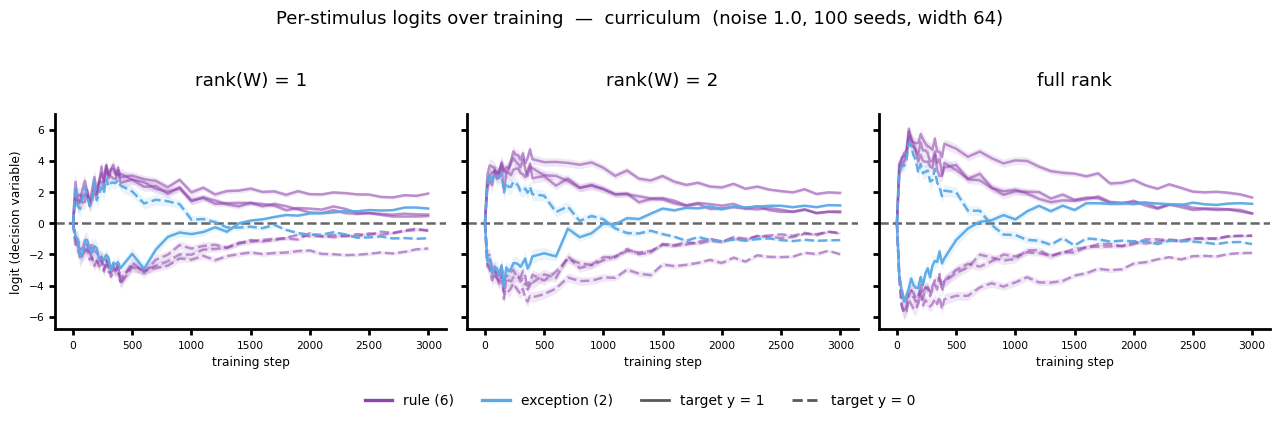

In [28]:
# --- Per-stimulus logits over training, one panel per rank ---
LOGIT_COND = 'curriculum'      # 'standard' / 'curriculum' / 'anti_curriculum'
SHOW_SEM   = True              # ±1 SEM band (over seeds) around each stimulus
RULE_COLOR, EXC_COLOR = '#8e44ad', '#5aa9e6'      # purple = rule, light blue = exception

from blob_task import ALL_LABELS, IS_PERIPHERAL
from matplotlib.lines import Line2D
is_exc  = np.asarray(IS_PERIPHERAL)     # (8,) False×6 (rule) then True×2 (exception)
labels8 = np.asarray(ALL_LABELS)        # (8,) target 0/1 per prototype

fig, axes = plt.subplots(1, len(RANK_VALUES), figsize=(4.3 * len(RANK_VALUES), 3.6),
                         sharey=True, squeeze=False)
axes = axes[0]
for ci, r in enumerate(RANK_VALUES):
    d = rank_runs[r]
    steps = d['checkpoints']
    L = d[f'{LOGIT_COND}_prototype_logits'][0]          # (8, T) — noise index 0
    Lsem = d.get(f'{LOGIT_COND}_prototype_logits_sem')
    Lsem = Lsem[0] if Lsem is not None else None
    ax = axes[ci]
    ax.axhline(0, ls='--', lw=1.2, color='black', alpha=0.6, zorder=1)   # decision boundary
    for s in range(L.shape[0]):
        col = EXC_COLOR if is_exc[s] else RULE_COLOR
        ls  = '-' if labels8[s] == 1 else '--'          # linestyle = target label
        ax.plot(steps, L[s], ls=ls, color=col, lw=1.8, zorder=3,
                alpha=0.95 if is_exc[s] else 0.55)
        if SHOW_SEM and Lsem is not None:
            ax.fill_between(steps, L[s] - Lsem[s], L[s] + Lsem[s],
                            color=col, alpha=0.12, lw=0, zorder=2)
    ax.set_title('full rank' if r is None else f'rank(W) = {r}', fontsize=12)
    ax.set_xlabel('training step')
    if ci == 0:
        ax.set_ylabel('logit (decision variable)')
    format_axis(ax, 1, 0.55)
    for ln in ax.lines:
        ln.set_linewidth(1.8)

handles = [Line2D([0], [0], color=RULE_COLOR, lw=2.4, label='rule (6)'),
           Line2D([0], [0], color=EXC_COLOR,  lw=2.4, label='exception (2)'),
           Line2D([0], [0], color='0.35', lw=2.0, ls='-',  label='target y = 1'),
           Line2D([0], [0], color='0.35', lw=2.0, ls='--', label='target y = 0')]
fig.legend(handles=handles, frameon=False, fontsize=10, ncol=4,
           loc='lower center', bbox_to_anchor=(0.5, -0.10))
fig.suptitle(f'Per-stimulus logits over training  —  {LOGIT_COND}  '
             f'(noise {FIG_NOISE}, {FIG_SEEDS} seeds, width {FIG_HIDDEN})',
             y=1.04, fontsize=13)
plt.tight_layout(); plt.show()


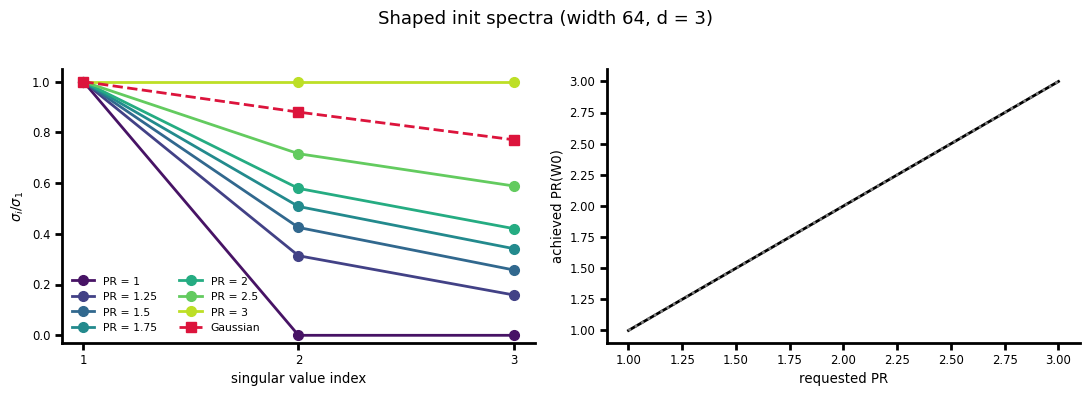

In [9]:
from blob_training import spectrum_for_pr, random_init_state
PR_VALUES = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]

cmap = plt.cm.viridis(np.linspace(0.05, 0.9, len(PR_VALUES)))
Wf = random_init_state(400, FIG_HIDDEN, FIG_INIT, 0.01, False,
                       torch.Generator(device=DEVICE).manual_seed(0), DEVICE)['W0']
gs = torch.linalg.svdvals(Wf).mean(0).cpu().numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
idx = np.arange(1, 4)
for c, pr in zip(cmap, PR_VALUES):
    s = spectrum_for_pr(pr, 3)
    ax[0].plot(idx, s / s[0], '-o', color=c, ms=7, lw=2, label=f'PR = {pr:g}')
ax[0].plot(idx, gs / gs[0], '--s', color='crimson', ms=7, lw=2, label='Gaussian')
ax[0].set_xticks(idx); ax[0].set_xlabel('singular value index')
ax[0].set_ylabel(r'$\sigma_i / \sigma_1$'); ax[0].set_ylim(-0.03, 1.05)
ax[0].legend(frameon=False, fontsize=8, ncol=2)

grid = np.linspace(1.0, 3.0, 200)
ach = [((spectrum_for_pr(p, 3)**2).sum()**2) / ((spectrum_for_pr(p, 3)**4).sum()) for p in grid]
ax[1].plot(grid, ach, '-', color='k', lw=2.2)
ax[1].plot(grid, grid, ':', color='gray', lw=1.2)
ax[1].set_xlabel('requested PR'); ax[1].set_ylabel('achieved PR(W0)')
for a in ax:
    format_axis(a, 1, 0.6)
    for ln in a.lines: ln.set_linewidth(2.0)
fig.suptitle(f'Shaped init spectra (width {FIG_HIDDEN}, d = 3)', y=1.03, fontsize=13)
plt.tight_layout(); plt.show()


T=1500 done
T=2000 done
T=2500 done
T=3000 done
T=5000 done
T=10000 done


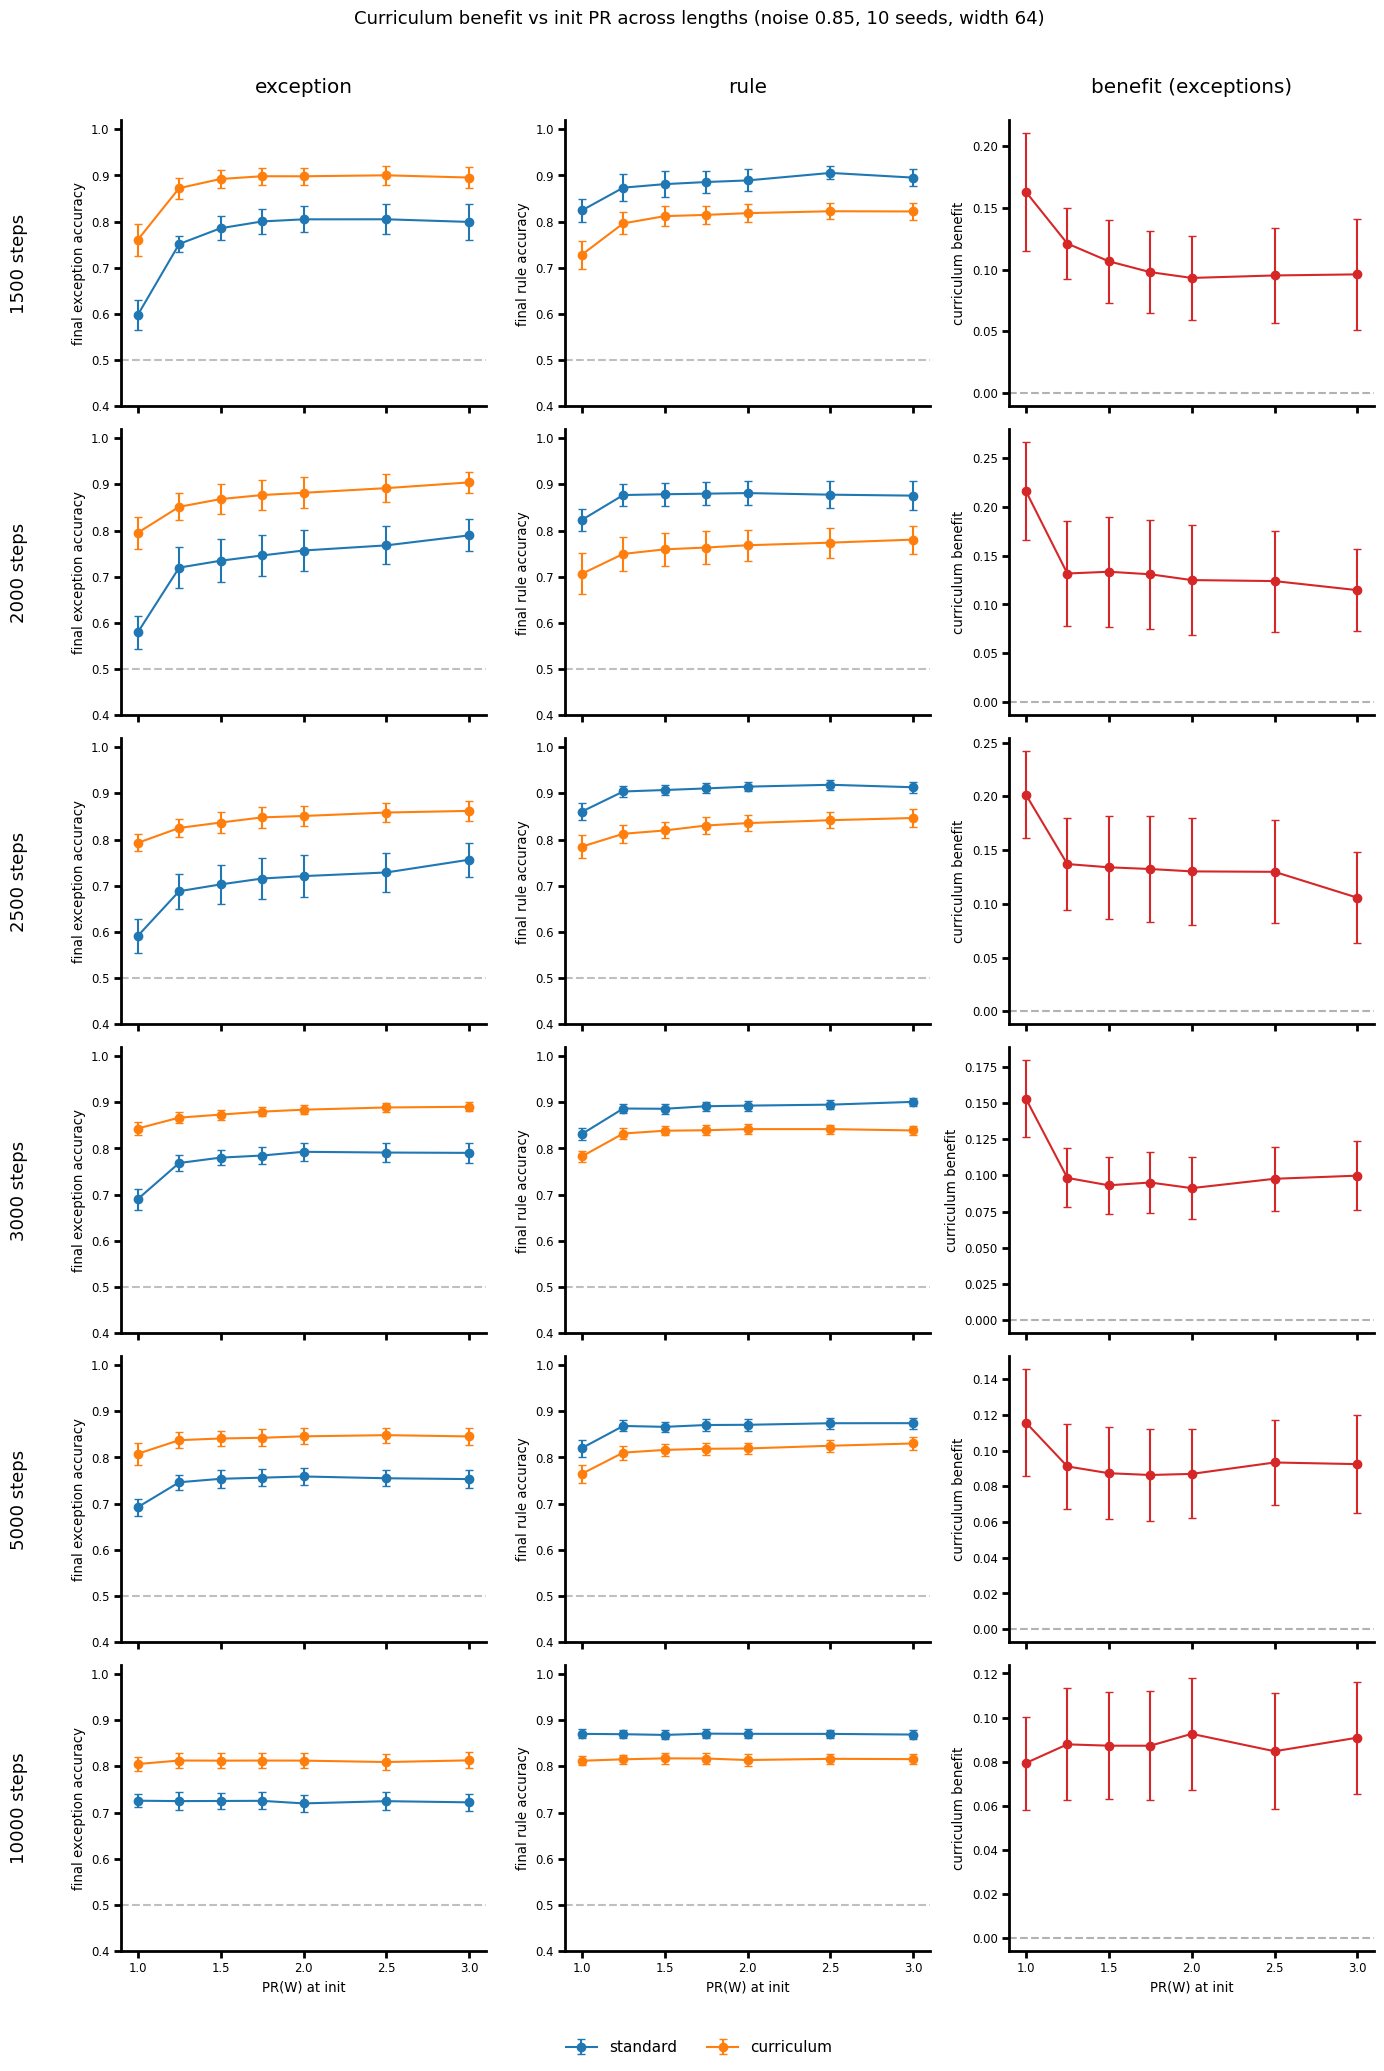

In [12]:
STEP_VALUES = [1500, 2000, 2500, 3000, 5000, 10000]   # rows; each needs its OWN run (see note)

pr_step_runs = {}
for T in STEP_VALUES:
    for p in PR_VALUES:
        pr_step_runs[(T, p)] = blob_experiments.compute_curve_data(
            make_config(), task, noise_levels=[FIG_NOISE], n_hidden=FIG_HIDDEN,
            weight_init_std=FIG_INIT, num_steps=T, num_seeds=FIG_SEEDS,
            checkpoints=[T], accuracy_mode=accuracy_mode, pr_target=p,
            output_temperature=FIG_TEMP, readout_init_std=FIG_READOUT_INIT)
    print(f'T={T} done')

GROUPS = (('peripheral', 'exception'), ('central', 'rule'))
nrow, ncol = len(STEP_VALUES), 3
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.3 * nrow),
                         sharex=True, squeeze=False)
for ri, T in enumerate(STEP_VALUES):
    for j, (key, name) in enumerate(GROUPS):
        ax = axes[ri][j]
        for cond, col in (('standard', 'C0'), ('curriculum', 'C1')):
            m = [pr_step_runs[(T, p)][f'{cond}_{key}'][0, -1] for p in PR_VALUES]
            e = [pr_step_runs[(T, p)][f'{cond}_{key}_sem'][0, -1] for p in PR_VALUES]
            ax.errorbar(PR_VALUES, m, yerr=e, marker='o', ms=6, capsize=3,
                        color=col, label=cond)
        ax.axhline(0.5, ls='--', lw=1, color='gray', alpha=0.5)
        ax.set_ylim(0.4, 1.02); ax.set_ylabel(f'final {name} accuracy')
        if ri == 0: ax.set_title(name, fontsize=12)
        if ri == nrow - 1: ax.set_xlabel('PR(W) at init')
    ax = axes[ri][2]
    ben = [pr_step_runs[(T, p)]['curriculum_peripheral'][0, -1]
           - pr_step_runs[(T, p)]['standard_peripheral'][0, -1] for p in PR_VALUES]
    bse = [np.hypot(pr_step_runs[(T, p)]['curriculum_peripheral_sem'][0, -1],
                    pr_step_runs[(T, p)]['standard_peripheral_sem'][0, -1]) for p in PR_VALUES]
    ax.axhline(0, ls='--', lw=1, color='gray', alpha=0.6)
    ax.errorbar(PR_VALUES, ben, yerr=bse, marker='o', ms=6, capsize=3, color='C3')
    ax.set_ylabel('curriculum benefit')
    if ri == 0: ax.set_title('benefit (exceptions)', fontsize=12)
    if ri == nrow - 1: ax.set_xlabel('PR(W) at init')
    for a in axes[ri]: format_axis(a, 1, 0.6)
    axes[ri][0].annotate(f'{T} steps', xy=(-0.28, 0.5), xycoords='axes fraction',
                         rotation=90, va='center', ha='center', fontsize=13)
h, l = axes[0][0].get_legend_handles_labels()
fig.legend(h, l, frameon=False, fontsize=11, ncol=2, loc='lower center',
           bbox_to_anchor=(0.5, -0.03))
fig.suptitle(f'Curriculum benefit vs init PR across lengths (noise {FIG_NOISE}, '
             f'{FIG_SEEDS} seeds, width {FIG_HIDDEN})', y=1.01, fontsize=13)
plt.tight_layout(); plt.show()


## Human data loading

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json
import ast
from simplicitybias.boolean_utils import *
# from simplicitybias.hmm import BooleanHMM
from itertools import combinations
import scipy.stats as stats
import pandas as pd
pd.set_option('display.max_columns', None)  # Show all columns in DataFrame display
from plotnine import (
    ggplot, aes, geom_line, geom_point, geom_errorbar, facet_wrap,
    labs, theme_classic, theme, element_text, geom_vline, scale_y_continuous, geom_hline, scale_x_continuous, scale_color_manual, ggtitle, scale_shape_manual, position_dodge
)

def load_json_files(root_dir):
    data = []
    debrief_data = []
    for root, dirs, files in os.walk(root_dir):
        for file in files:
            if file.endswith('.txt'):
                file_path = os.path.join(root, file)
                try:
                    with open(file_path, 'r') as f:
                        json_data = json.load(f)
                        if not isinstance(json_data, list):
                            json_data = [json_data]
                        # check if the first key is "metadata"
                        if "metadata" in json_data[0].keys():
                            data.append(json_data)
                        else:
                            debrief_data.append(json_data)
                except json.JSONDecodeError:
                    print(f"Error decoding JSON in file: {file_path}")
                except Exception as e:
                    print(f"Error reading file {file_path}: {str(e)}")
    return data, debrief_data


def convert_to_dataframe(loaded_data):
    all_data = []
    for idx, subj_data in enumerate(loaded_data):
        metadata = subj_data[0]['metadata']
        for entry in subj_data[1:]:
            row = {**metadata, **entry, 'subjectId': idx}
            all_data.append(row)
    df = pd.DataFrame(all_data)
    return df

root_directory = "/mnt/big/jirko/simplicitybias/data/curriculum_gradual_v2"
loaded_data, loaded_debrief_data = load_json_files(root_directory)

df = convert_to_dataframe(loaded_data)
df = df[df['taskPart'].notna()]
df = df[df['catch'] == False]
df = df[['timeout','subjectId','rt','correctResponse','stimuli','catch','taskPart','responseCoded','correct','trialNum','blockNum','curriculumCondition']]
# hardcoded for type 5 problem
exceptions = ['110','100']
df['stimType'] = df['stimuli'].apply(lambda x: 'Exception' if x in exceptions else 'Rule')
stimColors = {'Rule': '#8e7cc3ff', 'Exception': '#6fa8dcff'}
# remove all rows of subjects which have a trial number larger than 51
subjects_to_remove = df[df['trialNum'] > 51]['subjectId'].unique()
df = df[~df['subjectId'].isin(subjects_to_remove)]

curriculum_map = {
    "simple_to_complex": "Simple\nTo Complex",
    "complex_to_simple": "Complex\nTo Simple",
    "no_curriculum": "No\nCurriculum"
}
df['curriculum'] = df['curriculumCondition'].apply(lambda x: curriculum_map[x])
df['correct'] = df['correct'].astype(int)

#  Count unique participants per curriculum (uses existing `df`)
n_per_curr = df.groupby('curriculum')['subjectId'].nunique().reset_index(name='n')
print(n_per_curr)
print("Total participants:", n_per_curr['n'].sum())

           curriculum   n
0  Complex\nTo Simple  31
1      No\nCurriculum  34
2  Simple\nTo Complex  26
Total participants: 91


n_subjects per condition:
curriculum
Complex\nTo Simple    31
No\nCurriculum        34
Simple\nTo Complex    26
Name: subjectId, dtype: int64 



/tmp/ipykernel_618643/2256928451.py:125: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


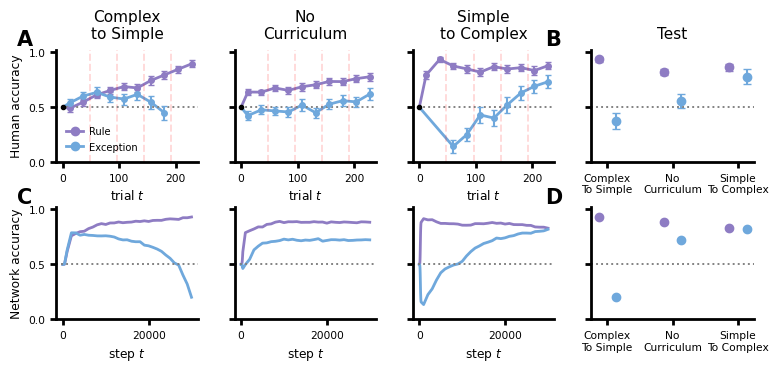

In [15]:
# ===== Figure 3: humans (top) vs networks (bottom) — learning dynamics + test =====
import sys, numpy as np, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
sys.path.insert(0, '/mnt/big/jirko/simplicitybias')
from simplicitybias.plot_utils import format_axis

stimColors = {'Rule': '#8e7cc3ff', 'Exception': '#6fa8dcff'}
CURR_ORDER = ['Complex\nTo Simple', 'No\nCurriculum', 'Simple\nTo Complex']   # human `curriculum` values
NN_CONDS   = ['anti_curriculum',   'standard',       'curriculum']            # aligned to CURR_ORDER
FONT_SCALE    = 0.55
TITLE_SIZE    = 11        # heading size (applied AFTER format_axis so it sticks)
bs            = 24       # human bin size (trials)
ADD_TEST_STAR = False     # <- toggle: draw test accuracy as a connected star at the end of each learning curve
LINE_WIDTH = 2   # add near the top with the other knobs

# --- n per condition ---
print('n_subjects per condition:')
print(df.groupby('curriculum')['subjectId'].nunique().reindex(CURR_ORDER), '\n')

# --- human summaries (learning binned over trials; test per subject) ---
dl = df[df['taskPart'] == 'learning'].copy()
dl['tt'] = dl.sort_values(['subjectId', 'blockNum', 'trialNum']).groupby('subjectId').cumcount() + 1
dl['bin_mid'] = ((dl['tt'] - 1) // bs) * bs + bs / 2
per_sub = dl.groupby(['curriculum', 'subjectId', 'stimType', 'bin_mid'], as_index=False).agg(acc=('correct', 'mean'))
learn = per_sub.groupby(['curriculum', 'stimType', 'bin_mid'], as_index=False).agg(
    m=('acc', 'mean'), se=('acc', lambda x: x.std(ddof=1) / np.sqrt(len(x))))
maxtrial = int(dl['tt'].max())
dt = df[df['taskPart'] == 'test']
pst = dt.groupby(['curriculum', 'subjectId', 'stimType'], as_index=False).agg(acc=('correct', 'mean'))
test = pst.groupby(['curriculum', 'stimType'], as_index=False).agg(
    m=('acc', 'mean'), se=('acc', lambda x: x.std(ddof=1) / np.sqrt(len(x))))

# --- NN from fig2_data (single noise); raw steps on x ---
d = fig2_data
ck = np.asarray(d['checkpoints']); maxstep = int(ck.max())

def letter(ax, t):
    ax.text(-0.28, 1.18, t, transform=ax.transAxes, fontsize=15, fontweight='bold', va='top', ha='left')
def style(ax, title=None):
    format_axis(ax, line_width_multiplier=1, font_size_multiplier=FONT_SCALE)
    if title is not None:
        ax.set_title(title, fontsize=TITLE_SIZE, pad=8)   # after format_axis so size sticks
def htest(c, s):
    r = test[(test['curriculum'] == c) & (test['stimType'] == s)]; return r['m'].values[0], r['se'].values[0]
def ntest(cc, s):
    key = 'central' if s == 'Rule' else 'peripheral'; return d[f'{cc}_{key}'][0][-1], d[f'{cc}_{key}_sem'][0][-1]

fig = plt.figure(figsize=(9, 3.5))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 1.15], hspace=0.4, wspace=0.25)
xpos, dodge = np.arange(3), 0.13

def test_panel(ax, means_by_stim):
    for k, stim in enumerate(['Rule', 'Exception']):
        m, s = means_by_stim[stim]
        ax.errorbar(xpos + (k - 0.5) * 2 * dodge, m, yerr=s, fmt='o', ms=6, color=stimColors[stim], capsize=3)
    ax.axhline(0.5, ls=':', c='gray'); ax.set_ylim(0, 1.02)
    ax.set_xticks(xpos); ax.set_xticklabels(CURR_ORDER, fontsize=7)   # keep '\n' -> wrapped labels

# ---- row 0: humans (dots + errorbars, bin=24) ----
for j, c in enumerate(CURR_ORDER):
    ax = fig.add_subplot(gs[0, j])
    for stim in ['Rule', 'Exception']:
        s = learn[(learn['curriculum'] == c) & (learn['stimType'] == stim)].sort_values('bin_mid')
        x, m, se = s['bin_mid'].values, s['m'].values, s['se'].values
        xl, yl = np.concatenate([[0], x]), np.concatenate([[0.5], m])        # connect to 50% start
        if ADD_TEST_STAR:
            mt, st = htest(c, stim); xs = maxtrial + bs
            xl, yl = np.concatenate([xl, [xs]]), np.concatenate([yl, [mt]])  # connect to test star
        ax.plot(xl, yl, '-', color=stimColors[stim], lw=1.5, zorder=2)
        ax.errorbar(x, m, yerr=se, fmt='o', ms=4, color=stimColors[stim], capsize=2, zorder=3)
        if ADD_TEST_STAR:
            ax.errorbar([xs], [mt], yerr=[st], fmt='*', ms=13, color=stimColors[stim], capsize=2, zorder=4)
    ax.plot([0], [0.5], 'o', color='k', ms=3, zorder=5)                      # theoretical 50% start dot
    for xb in range(48, maxtrial, 48):                                       # block breaks every 48 trials
        ax.axvline(xb, ls='--', color='red', alpha=0.15, lw=1)
    ax.axhline(0.5, ls=':', c='gray'); ax.set_ylim(0, 1.02); ax.set_xlabel('trial $t$')
    if j == 0:
        ax.set_ylabel('Human accuracy'); letter(ax, 'A')
        handles = [Line2D([], [], color=stimColors['Rule'], marker='o', lw=2, label='Rule'),
           Line2D([], [], color=stimColors['Exception'], marker='o', lw=2, label='Exception')]
        ax.legend(handles=handles,frameon=False, fontsize=8, loc='lower left', handlelength=1.5, handletextpad=0.5)
    style(ax, c.replace('To ', 'to '))          # was: style(ax, c)
    if j > 0:
        ax.tick_params(labelleft=False)

ax = fig.add_subplot(gs[0, 3]); letter(ax, 'B')
test_panel(ax, {s: ([htest(c, s)[0] for c in CURR_ORDER], [htest(c, s)[1] for c in CURR_ORDER]) for s in ['Rule', 'Exception']})
ax.tick_params(labelleft=False)
style(ax, 'Test')

# ---- row 1: networks (line + SEM band over steps) ----
for j, (c, cc) in enumerate(zip(CURR_ORDER, NN_CONDS)):
    ax = fig.add_subplot(gs[1, j])
    for stim, key in [('Rule', 'central'), ('Exception', 'peripheral')]:
        y, ys = d[f'{cc}_{key}'][0], d[f'{cc}_{key}_sem'][0]
        ax.plot(ck, y, '-', color=stimColors[stim])
        ax.fill_between(ck, y - ys, y + ys, color=stimColors[stim], alpha=0.2, lw=0)
        if ADD_TEST_STAR:
            mt, st = ntest(cc, stim); xs = maxstep * 1.05
            ax.plot([ck[-1], xs], [y[-1], mt], '-', color=stimColors[stim], lw=1)
            ax.errorbar([xs], [mt], yerr=[st], fmt='*', ms=13, color=stimColors[stim], capsize=2)
    ax.axhline(0.5, ls=':', c='gray'); ax.set_ylim(0, 1.02); ax.set_xlabel('step $t$')
    if j == 0:
        ax.set_ylabel('Network accuracy'); letter(ax, 'C')
    style(ax)
    if j > 0:
        ax.tick_params(labelleft=False)
ax = fig.add_subplot(gs[1, 3]); letter(ax, 'D')
test_panel(ax, {s: ([ntest(cc, s)[0] for cc in NN_CONDS], [ntest(cc, s)[1] for cc in NN_CONDS]) for s in ['Rule', 'Exception']})
ax.tick_params(labelleft=False)
style(ax)

# --- thicken the solid data lines (must run AFTER format_axis, which resets line widths) ---
for ax in fig.axes:
    for ln in ax.get_lines():
        if ln.get_linestyle() == '-':        # skip the dotted 0.5 line and dashed block lines
            ln.set_linewidth(LINE_WIDTH)

# --- single Rule/Exception legend below all panels ---
# handles = [Line2D([], [], color=stimColors['Rule'], marker='o', lw=2, label='Rule'),
#            Line2D([], [], color=stimColors['Exception'], marker='o', lw=2, label='Exception')]
# fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=True, fontsize=8)

# fig.savefig('figure3_human_vs_nn.svg', bbox_inches='tight')
plt.tight_layout()
plt.show()


/tmp/ipykernel_618643/1912723043.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


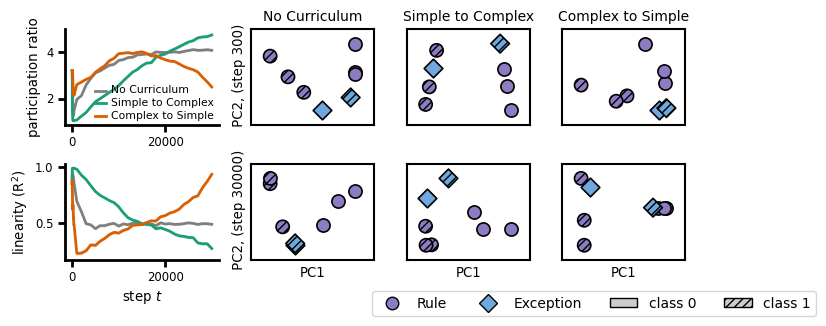

In [16]:
# ===== Mechanism: PR + linearity (col 0) and PCA over training (cols 1-3) =====
import sys, numpy as np, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
sys.path.insert(0, '/mnt/big/jirko/simplicitybias')
from simplicitybias.plot_utils import format_axis
from blob_task import ALL_LABELS, IS_PERIPHERAL

stimColors = {'Rule': '#8e7cc3ff', 'Exception': '#6fa8dcff'}
condColors = {'standard': '#7f7f7f', 'curriculum': '#1b9e77', 'anti_curriculum': '#d95f02'}
condLabel = {'standard': 'No Curriculum', 'curriculum': 'Simple to Complex', 'anti_curriculum': 'Complex to Simple'}
PCA_ROWS_STEPS = [FIG_SNAPS[0], FIG_SNAPS[2]]                    # top row = early, bottom row = final
PCA_CONDS      = ['standard', 'curriculum', 'anti_curriculum']  # columns 1-3
FONT_SCALE, LINE_WIDTH = 0.6, 2.0

d = fig2_data
steps = np.asarray(d['checkpoints']); conds = d['conditions']
labels, is_p = np.asarray(ALL_LABELS), np.asarray(IS_PERIPHERAL)

def band(ax, x, m, s, c, label=None):
    ax.plot(x, m, '-', color=c, label=label)
    if s is not None:
        ax.fill_between(x, m - s, m + s, color=c, alpha=0.2, lw=0)
def thicken(ax):                                        # format_axis resets line widths
    for ln in ax.get_lines():
        if ln.get_linestyle() == '-':
            ln.set_linewidth(LINE_WIDTH)
def scatter_pca(ax, proj):
    for is_exc in [False, True]:                         # colour/shape = rule / exception
        for cls in [0, 1]:                              # hatch = class (solid=0, hatched=1)
            msk = (is_p == is_exc) & (labels == cls)
            if msk.sum() == 0:
                continue
            ax.scatter(proj[msk, 0], proj[msk, 1], s=90, marker='D' if is_exc else 'o',
                       facecolor=stimColors['Exception' if is_exc else 'Rule'], edgecolor='k',
                       hatch='////' if cls == 1 else None, linewidths=1.2)
    format_axis(ax, 1, FONT_SCALE)
    for sp in ax.spines.values():                        # full frame
        sp.set_visible(True); sp.set_linewidth(1.5)
    ax.margins(0.22)                                     # extend axes so points aren't clipped

fig = plt.figure(figsize=(8, 3))
gs = GridSpec(2, 4, figure=fig, wspace=0.25, hspace=0.4, width_ratios=[1.25, 1, 1, 1])

# --- column 0: participation ratio (top) + decision linearity (bottom) ---
ax = fig.add_subplot(gs[0, 0])
for c in conds:
    band(ax, steps, d[f'{c}_participation_ratio'][0], d[f'{c}_participation_ratio_sem'][0], condColors[c], condLabel[c])
ax.set(xlabel=None, ylabel='participation ratio')
ax.legend(frameon=False, fontsize=4); format_axis(ax, 1, FONT_SCALE); thicken(ax)
ax = fig.add_subplot(gs[1, 0])
for c in conds:
    band(ax, steps, d[f'{c}_linearity'][0], d[f'{c}_linearity_sem'][0], condColors[c], condLabel[c])
ax.set(xlabel='step $t$', ylabel='linearity (R$^2$)')
format_axis(ax, 1, FONT_SCALE); thicken(ax)

# --- columns 1-3: PCA per condition; rows = steps; each cell uses its OWN basis (like the 1x5 figure) ---
for col, cond in enumerate(PCA_CONDS):
    ci = conds.index(cond)
    for row, tstep in enumerate(PCA_ROWS_STEPS):
        snap = min(d['snapshots'], key=lambda s: abs(s - tstep))
        reps = d['rep_snapshots'][snap][ci, 0]                 # (8, H), seed 0
        m = reps.mean(0, keepdims=True)
        _, _, vt = np.linalg.svd(reps - m, full_matrices=False)
        proj = (reps - m) @ vt[:2].T
        ax = fig.add_subplot(gs[row, 1 + col])
        scatter_pca(ax, proj)
        if row == 0:
            ax.set_title(condLabel[cond], fontsize=10)
        if row == len(PCA_ROWS_STEPS) - 1:
            ax.set_xlabel('PC1')
        if col == 0:
            ax.set_ylabel(f' PC2, (step {snap})')
        # increase the spine width for the PCA panels
        for sp in ax.spines.values():
            sp.set_linewidth(1.5)
        ax.set_xticks([]); ax.set_yticks([])


# --- legend for the point encoding (below everything) ---
handles = [Line2D([], [], marker='o', color='w', markerfacecolor=stimColors['Rule'], markeredgecolor='k', markersize=9, label='Rule'),
           Line2D([], [], marker='D', color='w', markerfacecolor=stimColors['Exception'], markeredgecolor='k', markersize=9, label='Exception'),
           Patch(facecolor='#cccccc', edgecolor='k', label='class 0'),
           Patch(facecolor='#cccccc', edgecolor='k', hatch='////', label='class 1')]
fig.legend(handles=handles, loc='lower left', bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=True, fontsize=10)

plt.tight_layout()
# fig.savefig('figure_mechanism.svg', bbox_inches='tight')
plt.show()


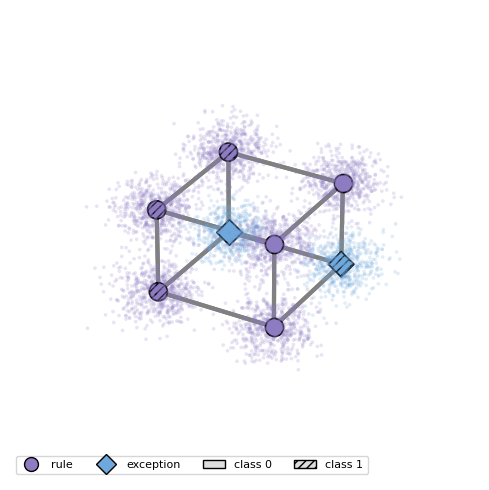

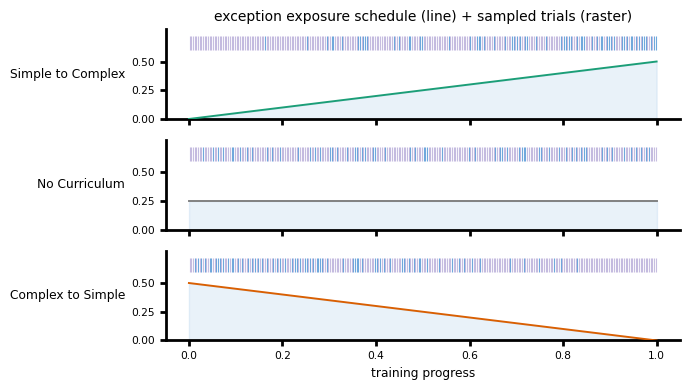

In [17]:
# ===== Figure 1 (NN task): feature-cube stimuli + continuous curricula (raster + line) =====
import sys, itertools, numpy as np, matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D             # noqa: F401
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
sys.path.insert(0, '/mnt/big/jirko/simplicitybias')
from simplicitybias.plot_utils import format_axis
from blob_task import ALL_PROTOTYPES, ALL_LABELS, IS_PERIPHERAL

stimColors = {'Rule': '#8e7cc3ff', 'Exception': '#6fa8dcff'}
# condColors = {'standard': '#7f7f7f', 'curriculum': '#1b9e77', 'anti_curriculum': '#d95f02'}
condColors = {'Simple to Complex': '#1b9e77', 'No Curriculum': '#7f7f7f', 'Complex to Simple': '#d95f02'}
TASK_NOISE, N_BLOB = 0.3, 600                        # illustrative blob spread (training uses larger)
rng = np.random.default_rng(0)
labels, is_p = np.asarray(ALL_LABELS), np.asarray(IS_PERIPHERAL)

# ---- (a) stimuli: colour=rule/exception, marker=circle/diamond, hatch=class; no grid ----
fig = plt.figure(figsize=(5.5, 5))
ax = fig.add_subplot(111, projection='3d')
corners = np.array(list(itertools.product([-1, 1], repeat=3)))
for a in corners:                                    # faint cube wireframe
    for b in corners:
        if np.sum(np.abs(a - b)) == 2:
            ax.plot(*zip(a, b), color='0.5', lw=3, zorder=1)
for p, lab, ise in zip(ALL_PROTOTYPES, labels, is_p):
    col = stimColors['Exception' if ise else 'Rule']
    ax.scatter(*(p + TASK_NOISE * rng.standard_normal((N_BLOB, 3))).T, s=7, color=col, alpha=0.20, edgecolors='none', zorder=2)
    ax.scatter(*[[v] for v in p], s=170, facecolor=col, edgecolor='k', linewidths=1.2,
               marker='D' if ise else 'o', hatch='////' if lab == 1 else None, zorder=3)
ax.set_xlabel('feature 1'); ax.set_ylabel('feature 2'); ax.set_zlabel('feature 3')
ax.set_xticks([-1, 1]); ax.set_yticks([-1, 1]); ax.set_zticks([-1, 1]); ax.grid(False)
for a3 in (ax.xaxis, ax.yaxis, ax.zaxis):            # remove background panes
    a3.pane.fill = False; a3.pane.set_edgecolor('w')
ax.legend(handles=[Line2D([], [], marker='o', color='w', markerfacecolor=stimColors['Rule'], markeredgecolor='k', markersize=10, label='rule'),
                   Line2D([], [], marker='D', color='w', markerfacecolor=stimColors['Exception'], markeredgecolor='k', markersize=10, label='exception'),
                   Patch(facecolor='#dddddd', edgecolor='k', label='class 0'),
                   Patch(facecolor='#dddddd', edgecolor='k', hatch='////', label='class 1')],
          loc='lower left', fontsize=8, frameon=True, ncol=4)
ax.set_axis_off()
plt.tight_layout()
# plt.savefig('figure1_stimuli.svg', bbox_inches='tight')
plt.show()

# ---- (b) curricula: exception schedule (line + area) + sampled-trial raster, per condition ----
CONDS, p, NT = ['Simple to Complex', 'No Curriculum', 'Complex to Simple'], 0.25, 280
def p_exc(cond, prog):
    return np.clip({'Simple to Complex': 2 * p * prog,
                    'Complex to Simple': 2 * p * (1 - prog)}.get(cond, np.full_like(prog, p)), 0, 1)
prog, tprog = np.linspace(0, 1, 300), (np.arange(NT) + 0.5) / NT
fig, axes = plt.subplots(len(CONDS), 1, figsize=(7, 4), sharex=True)
for ax, cond in zip(axes, CONDS):
    pe = p_exc(cond, prog)
    ax.plot(prog, pe, color=condColors[cond], lw=2.5, zorder=3)
    ax.fill_between(prog, 0, pe, color=stimColors['Exception'], alpha=0.15, zorder=1)
    isexc = rng.random(NT) < p_exc(cond, tprog)                                    # realized stream
    ax.vlines(tprog[isexc], 0.60, 0.72, color=stimColors['Exception'], lw=0.8)      # exception trials
    ax.vlines(tprog[~isexc], 0.60, 0.72, color=stimColors['Rule'], lw=0.8, alpha=0.5)  # rule trials
    ax.set_ylim(0, 0.78); ax.set_yticks([0, 0.25, 0.5])
    ax.set_ylabel(cond, fontsize=9, rotation=0, ha='right', va='center')
    format_axis(ax, 1, 0.55)
axes[-1].set_xlabel('training progress')
axes[0].set_title('exception exposure schedule (line) + sampled trials (raster)', fontsize=10)
plt.tight_layout()
# plt.savefig('figure1_curricula.svg', bbox_inches='tight')
plt.show()


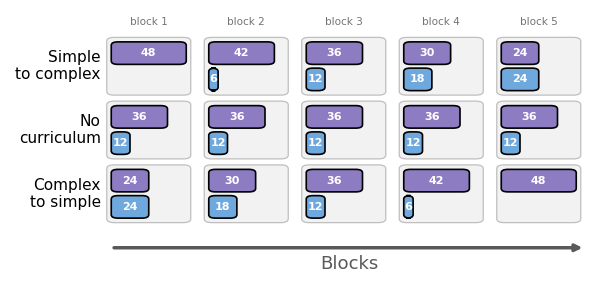

In [18]:
# ===== Figure 1 (humans): curriculum block structure (rounded, outlined, compact) =====
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

stimColors = {'Rule': '#8e7cc3ff', 'Exception': '#6fa8dcff'}
data = [('Simple\nto complex', ([48, 42, 36, 30, 24], [0, 6, 12, 18, 24])),
        ('No\ncurriculum',     ([36, 36, 36, 36, 36], [12, 12, 12, 12, 12])),
        ('Complex\nto simple', ([24, 30, 36, 42, 48], [24, 18, 12, 6, 0]))]
BLOCK_TRIALS, N = 48, 5
W, BH, GAP, CG, RG = 1.0, 0.30, 0.05, 1.3, 0.85   # bar unit len, bar height, intra-block gap, col gap, row gap

def block(ax, x, y, w, h, color, text):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0,rounding_size=0.09',
                                mutation_aspect=0.5, facecolor=color, edgecolor='k', linewidth=1.2, zorder=2))
    ax.text(x + w / 2, y + h / 2, str(text), ha='center', va='center',
            fontsize=8, color='white', fontweight='bold', zorder=3)



fig, ax = plt.subplots(figsize=(7.2, 3.0))
for ci, (cond, (rule, exc)) in enumerate(data):
    y0 = (len(data) - 1 - ci) * RG
    # for b in range(N):
    #     x0 = b * CG
    #     block(ax, x0, y0 + GAP / 2, rule[b] / BLOCK_TRIALS * W, BH, stimColors['Rule'], rule[b])
    #     if exc[b] > 0:
    #         block(ax, x0, y0 - GAP / 2 - BH, exc[b] / BLOCK_TRIALS * W, BH, stimColors['Exception'], exc[b])
    for b in range(N):
        x0 = b * CG
        # --- block slot: light rounded box behind the two bars (delineates the block) ---
        ax.add_patch(FancyBboxPatch((x0 - 0.06, y0 - GAP / 2 - BH - 0.06), W + 0.12, 2 * BH + GAP + 0.12,
                                    boxstyle='round,pad=0,rounding_size=0.10', mutation_aspect=0.5,
                                    facecolor='#f2f2f2', edgecolor='0.75', linewidth=0.9, zorder=0))
        if ci == 0:  # block number header on the top row only
            ax.text(x0 + W / 2, y0 + GAP / 2 + BH + 0.22, f'block {b + 1}', ha='center', fontsize=7.5, color='0.45')

        block(ax, x0, y0 + GAP / 2, rule[b] / BLOCK_TRIALS * W, BH, stimColors['Rule'], rule[b])
        if exc[b] > 0:
            block(ax, x0, y0 - GAP / 2 - BH, exc[b] / BLOCK_TRIALS * W, BH, stimColors['Exception'], exc[b])

    ax.text(-0.14, y0, cond, ha='right', va='center', fontsize=11)
ax.annotate('', xy=(N * CG - 0.18, -0.72), xytext=(0, -0.72), arrowprops=dict(arrowstyle='-|>', lw=2.5, color='0.35'))
ax.text((N * CG - 0.15) / 2, -1.0, 'Blocks', ha='center', fontsize=13, color='0.35')
ax.set_xlim(-1.35, N * CG + 0.05); ax.set_ylim(-1.1, (len(data) - 1) * RG + BH + GAP)
ax.set_ylim(-1.15, (len(data) - 1) * RG + BH + GAP + 0.4)
ax.axis('off'); ax.set_aspect('equal')
# fig.savefig('figure1_human_curriculum.svg', bbox_inches='tight')
plt.tight_layout(); plt.show()


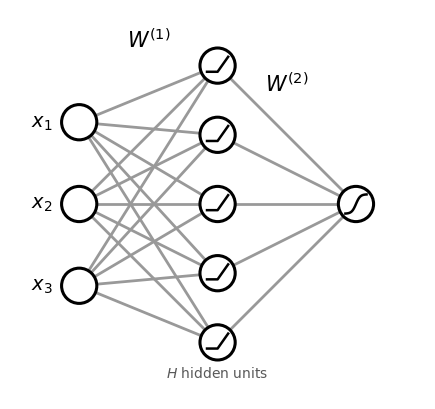

In [19]:
# ===== NN schematic: 3-D input -> H ReLU units -> sigmoid output =====
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Circle

SHOW_WEIGHTS   = True          # toggle W^(1) / W^(2) labels
N_HIDDEN_SHOWN = 5             # units drawn (schematic; the real net has 64)
R              = 0.28          # neuron radius
WEIGHT_COLORS  = ('k', 'k')    # e.g. ('#c0347f', '#2b8cbe') to colour W^(1)/W^(2)

def node(ax, x, y, glyph=None):
    ax.add_patch(Circle((x, y), R, facecolor='white', edgecolor='k', lw=2.2, zorder=3))
    if glyph == 'relu':                                   # flat then rising (ReLU)
        ax.plot(x + np.array([-.6, 0, .6]) * R, y + np.array([-.35, -.35, .5]) * R, 'k', lw=1.8, zorder=4)
    elif glyph == 'sigmoid':                              # S-curve
        t = np.linspace(-1, 1, 40); s = 1 / (1 + np.exp(-5 * t))
        ax.plot(x + t * .6 * R, y + (s - .5) * 1.1 * R, 'k', lw=1.8, zorder=4)

xin, xh, xo = 0.0, 2.2, 4.4
yin, yh, yo = [1.3, 0.0, -1.3], np.linspace(2.2, -2.2, N_HIDDEN_SHOWN), 0.0

fig, ax = plt.subplots(figsize=(6.2, 4.2))
for yi in yin:                                            # input -> hidden edges
    for yhh in yh:
        ax.plot([xin, xh], [yi, yhh], color='0.6', lw=2, zorder=1)
for yhh in yh:                                            # hidden -> output edges
    ax.plot([xh, xo], [yhh, yo], color='0.6', lw=2, zorder=1)
for i, yi in enumerate(yin):
    node(ax, xin, yi); ax.text(xin - R - 0.15, yi, f'$x_{i+1}$', ha='right', va='center', fontsize=14)
for yhh in yh:
    node(ax, xh, yhh, 'relu')
node(ax, xo, yo, 'sigmoid')

# ax.text(xo + R + 0.15, yo, 'choice', ha='left', va='center', fontsize=13)
if SHOW_WEIGHTS:
    ax.text((xin + xh) / 2, 2.5, r'$W^{(1)}$', ha='center', fontsize=15, color=WEIGHT_COLORS[0])
    ax.text((xh + xo) / 2, 1.8, r'$W^{(2)}$', ha='center', fontsize=15, color=WEIGHT_COLORS[1])
ax.text(xh, -2.75, '$H$ hidden units', ha='center', fontsize=10, color='0.35')
ax.set_xlim(-1.1, 5.5); ax.set_ylim(-3.1, 3.1); ax.axis('off'); ax.set_aspect('equal')
# fig.savefig('nn_schematic.svg', bbox_inches='tight')
plt.tight_layout(); plt.show()


In [197]:
# === Experiment 2: pretraining (1-D rule vs XOR) -> type-5 transfer ===
import blob_pretrain as bp2

# PRE_NOISE     = 0.85     # transfer + pretrain input-noise std (matches FIG_NOISE)
# TRAN_NOISE    = 0.85     # transfer input-noise std (matches FIG_NOISE)
# PRE_HIDDEN    = 64       # width  (rich regime, as in Figure 2)
# PRE_INIT      = 0.005    # weight_init_std (rich / feature-learning)
# PRE_PRE       = 20000     # pretraining steps
# PRE_TRANSFER  = 2000    # type-5 transfer steps
# PRE_SEEDS     = 10       # nets per (kind x schedule); more = tighter bands
# PRE_KINDS     = ('none', '1d', 'xor')
# RESET_READOUT = False   # True = carry over only pretrained features (fresh readout)
# ACCURACY_MODE = 'expected'   # <- TOGGLE: 'expected' (soft/sigmoid) or 'argmax' (hard 0/1)

PRE_NOISE     = 0.0     # transfer + pretrain input-noise std (matches FIG_NOISE)
TRAN_NOISE    = 0.85     # transfer input-noise std (matches FIG_NOISE)
PRE_HIDDEN    = 64       # width  (rich regime, as in Figure 2)
PRE_INIT      = 0.005    # weight_init_std (rich / feature-learning)
PRE_PRE       = 10000     # pretraining steps
PRE_TRANSFER  = 1500    # type-5 transfer steps
PRE_SEEDS     = 50       # nets per (kind x schedule); more = tighter bands
PRE_KINDS     = ('none', '1d', 'xor')
RESET_READOUT = True   # True = carry over only pretrained features (fresh readout)
ACCURACY_MODE = 'expected'   # <- TOGGLE: 'expected' (soft/sigmoid) or 'argmax' (hard 0/1)



pt = bp2.train_pretrain_transfer(
    make_config(weight_init_std=PRE_INIT, n_hidden=PRE_HIDDEN, accuracy_mode=ACCURACY_MODE),
    task, transfer_noise=TRAN_NOISE, pretrain_noise=PRE_NOISE,
    pretrain_steps=PRE_PRE, transfer_steps=PRE_TRANSFER, num_seeds=PRE_SEEDS,
    pretrain_kinds=PRE_KINDS, reset_readout=RESET_READOUT)
print('pretrain->transfer ready; kinds', pt['pretrain_kinds'],
      '| reset_readout', pt['reset_readout'])


pretrain->transfer ready; kinds ['none', '1d', 'xor'] | reset_readout True


Pretraining -> type-5 transfer  |  noise 0.85, 50 seeds, width 64, pretrain 10000 / transfer 1500 steps  [readout reset]
       prior       sched |  excep   rule   PR0   PRf
----------------------------------------------------
from scratch    standard |  0.515  0.801  3.20  2.01
from scratch  curriculum |  0.534  0.714  3.20  1.84
             curr-benefit | +0.020 +/- 0.004 on exceptions

    1-D rule    standard |  0.564  0.817  1.00  2.18
    1-D rule  curriculum |  0.720  0.714  1.00  2.43
             curr-benefit | +0.156 +/- 0.009 on exceptions  <pretrain PR 1.00>

         XOR    standard |  0.644  0.821  3.00  3.16
         XOR  curriculum |  0.734  0.742  3.00  3.18
             curr-benefit | +0.090 +/- 0.006 on exceptions  <pretrain PR 3.00>



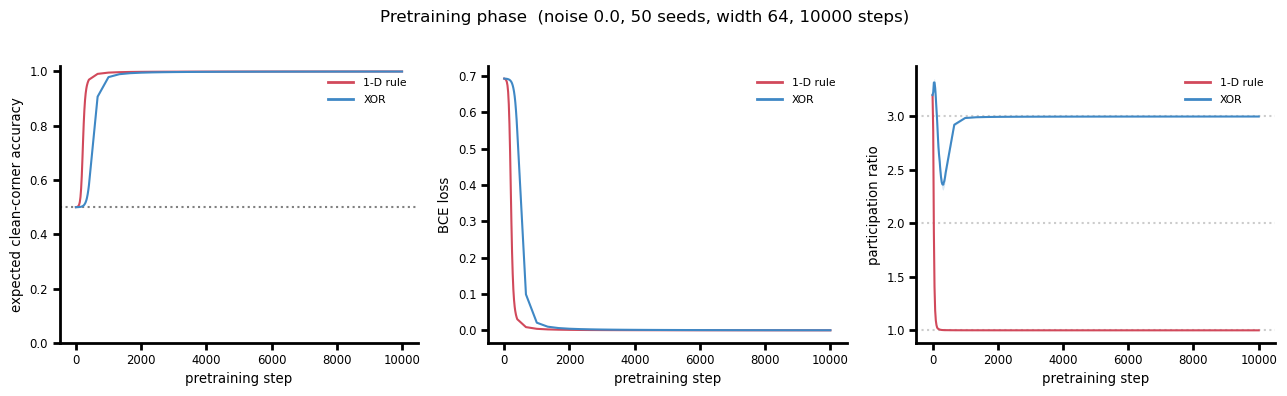

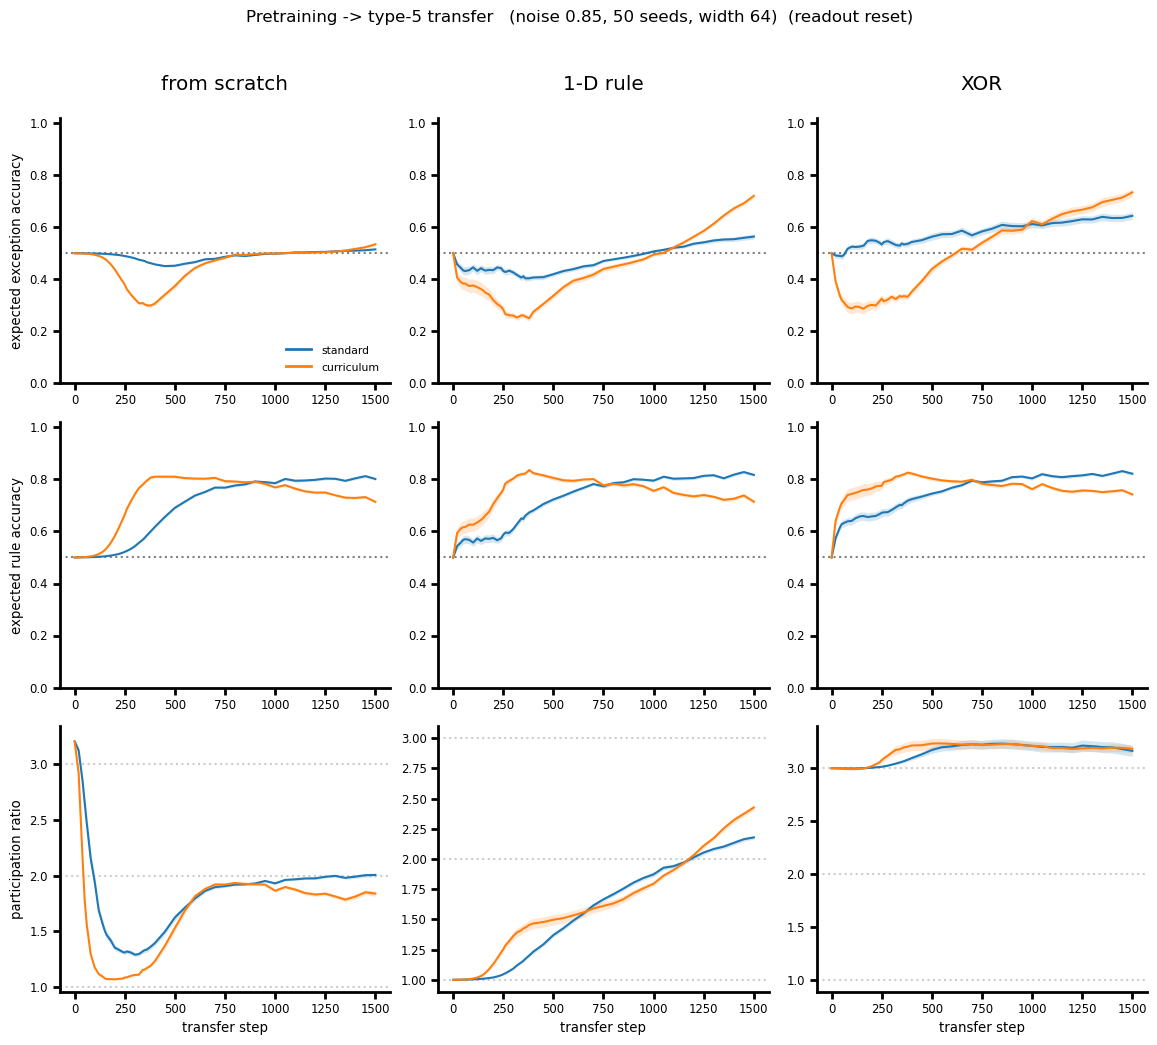

In [198]:
bp2.plot_pretrain_curves(pt)                            # NEW: pretraining phase — accuracy, loss, PR over training
bp2.plot_pretrain_transfer(pt)                          # Fig-4 analog: exception acc + PR, per kind
# bp2.plot_compression_predicts_benefit(pt, kind='1d')    # Fig-5C analog: PR -> benefit scatter
bp2.pretrain_summary(pt)                                # numeric table + curriculum benefit


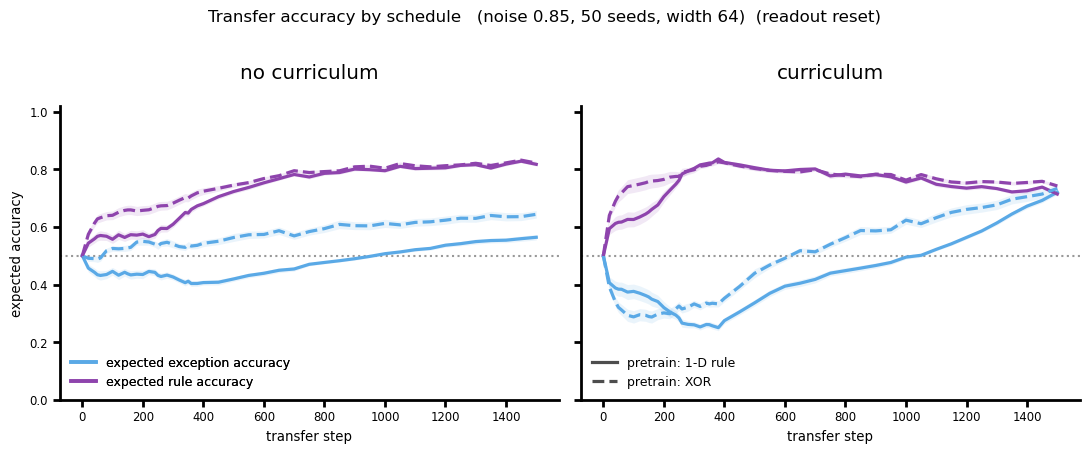

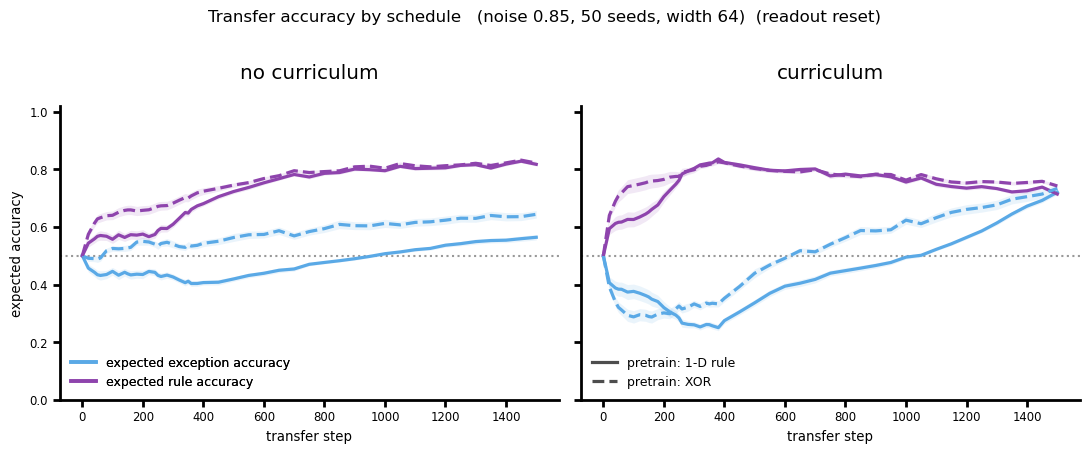

In [199]:
bp2.plot_transfer_by_schedule(pt, kinds=('1d', 'xor'))   # 2 panels; 4 lines each (blue=excep, purple=rule; solid=1d, dashed=xor)

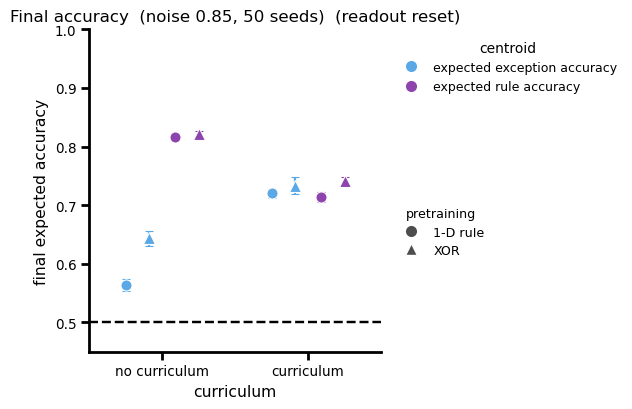

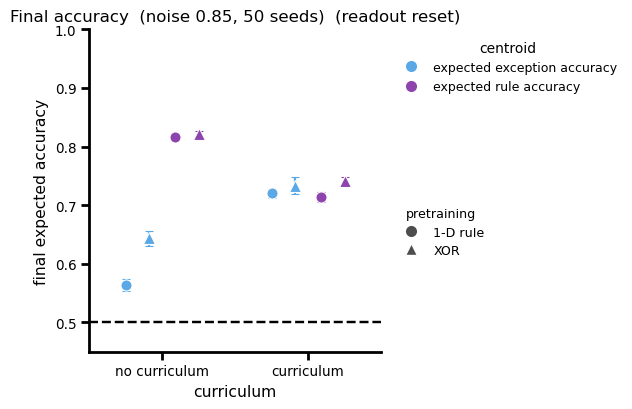

In [200]:
bp2.plot_final_accuracy_by_schedule(pt, kinds=('1d', 'xor'), ylim=(0.45, 1))   # final acc; colour=centroid type, marker=pretraining, x=curriculum

In [192]:
# === Experiment 2: pretraining (1-D rule vs XOR) -> type-5 transfer ===
import blob_pretrain as bp2

PRE_NOISE     = 0.00     # transfer + pretrain input-noise std
TRAN_NOISE    = 0.85     # transfer input-noise std (matches FIG_NOISE)
PRE_HIDDEN    = 64       # width (rich regime, as in Figure 2)
PRE_INIT      = 0.005    # weight_init_std (rich / feature-learning)
ADAP_INIT     = 0.1     # weight_init_std for linear input adapter (if used)
PRE_PRE       = 20000     # pretraining steps
PRE_TRANSFER  = 2500    # type-5 transfer steps
PRE_SEEDS     = 20       # nets per (kind x schedule)
PRE_KINDS     = ('none', '1d', 'xor')
RESET_READOUT = True    # True = carry over only pretrained features (fresh readout)
ADAPTER       = True    # <- TOGGLE: reset a linear input adapter between pretrain & transfer
ADAPTER_DIM   = 6        # adapter latent width (only used when ADAPTER=True)
ACCURACY_MODE = 'expected'   # 'expected' (soft/sigmoid) or 'argmax' (hard 0/1)

pt = bp2.train_pretrain_transfer(
    make_config(weight_init_std=PRE_INIT, n_hidden=PRE_HIDDEN, accuracy_mode=ACCURACY_MODE),
    task, transfer_noise=TRAN_NOISE, pretrain_noise=PRE_NOISE,
    pretrain_steps=PRE_PRE, transfer_steps=PRE_TRANSFER, num_seeds=PRE_SEEDS,
    pretrain_kinds=PRE_KINDS, reset_readout=RESET_READOUT,
    adapter=ADAPTER, adapter_dim=ADAPTER_DIM, adapter_init_std=ADAP_INIT)
print('ready; accuracy_mode', pt['accuracy_mode'], '| reset_readout', pt['reset_readout'],
      '| adapter', pt['adapter'])


ready; accuracy_mode expected | reset_readout True | adapter True


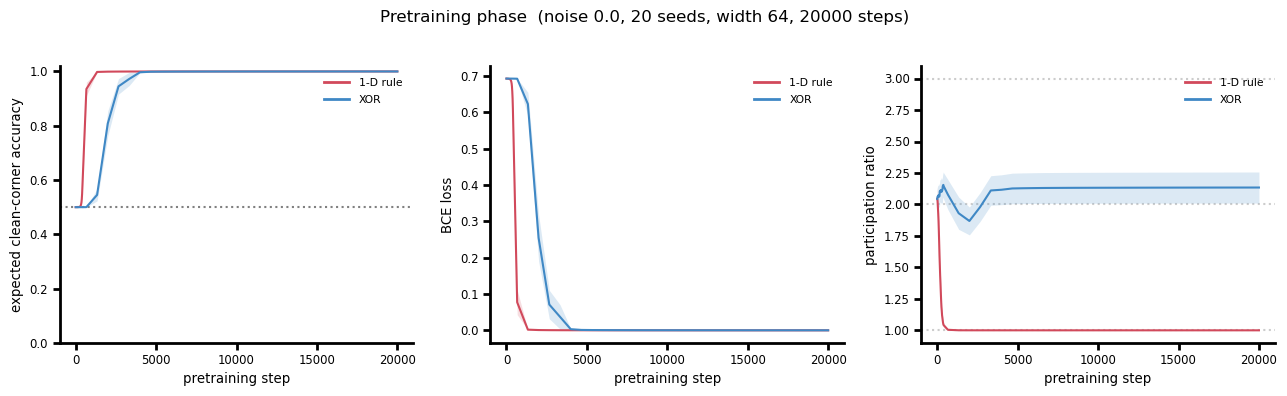

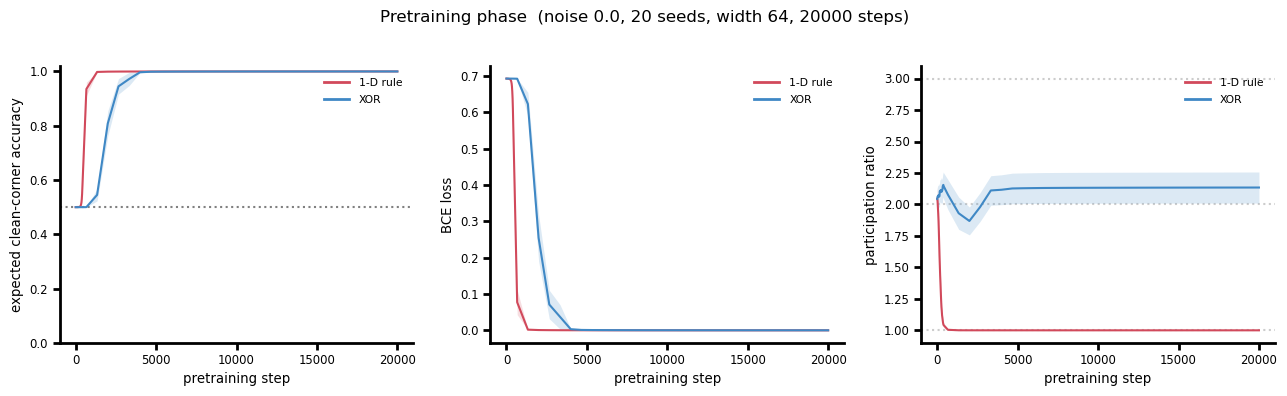

In [193]:
bp2.plot_pretrain_curves(pt)                            # NEW: pretraining phase — accuracy, loss, PR over training
                        # Fig-4 analog: exception acc + PR, per kind

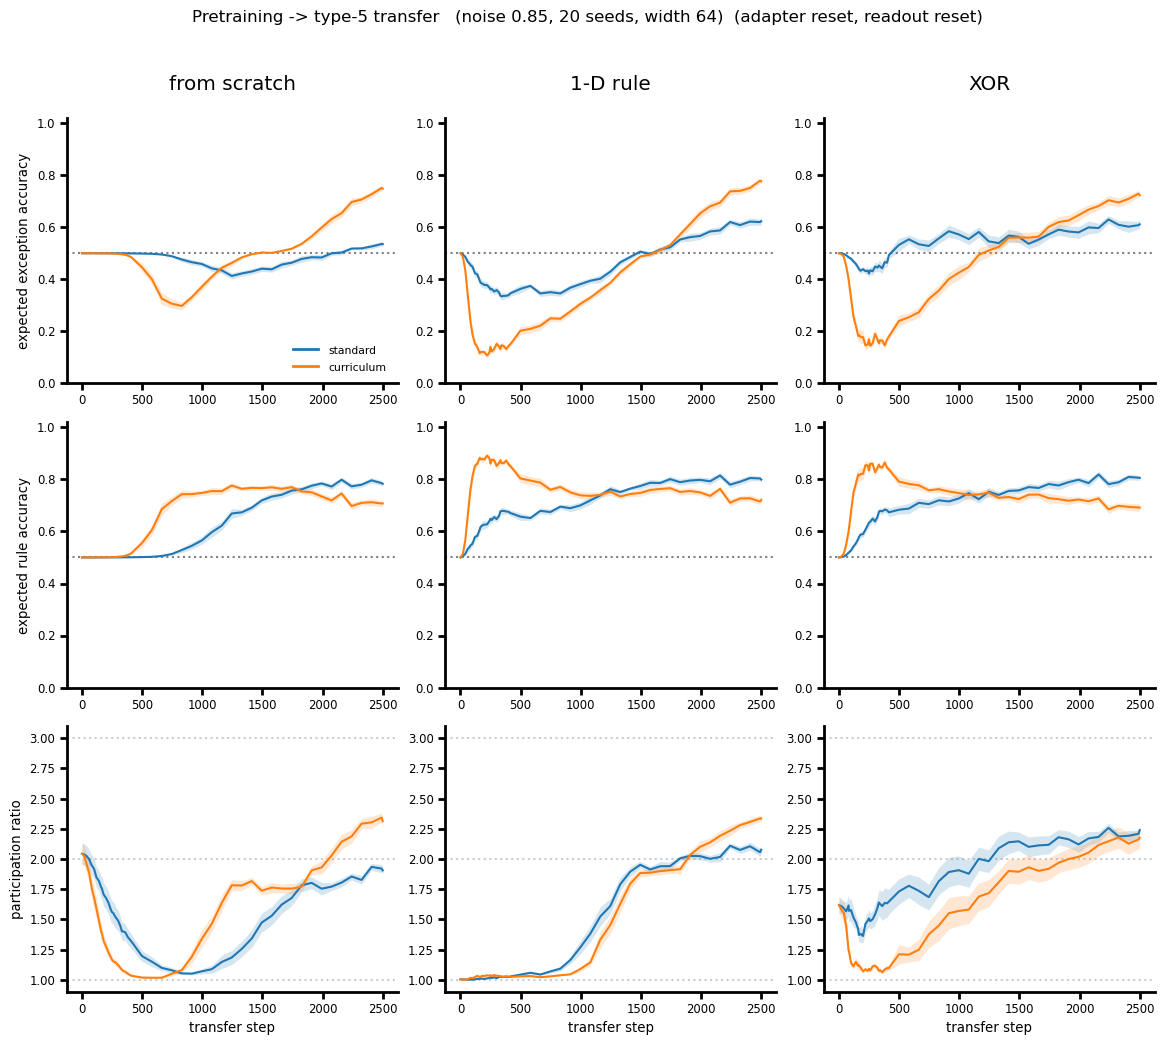

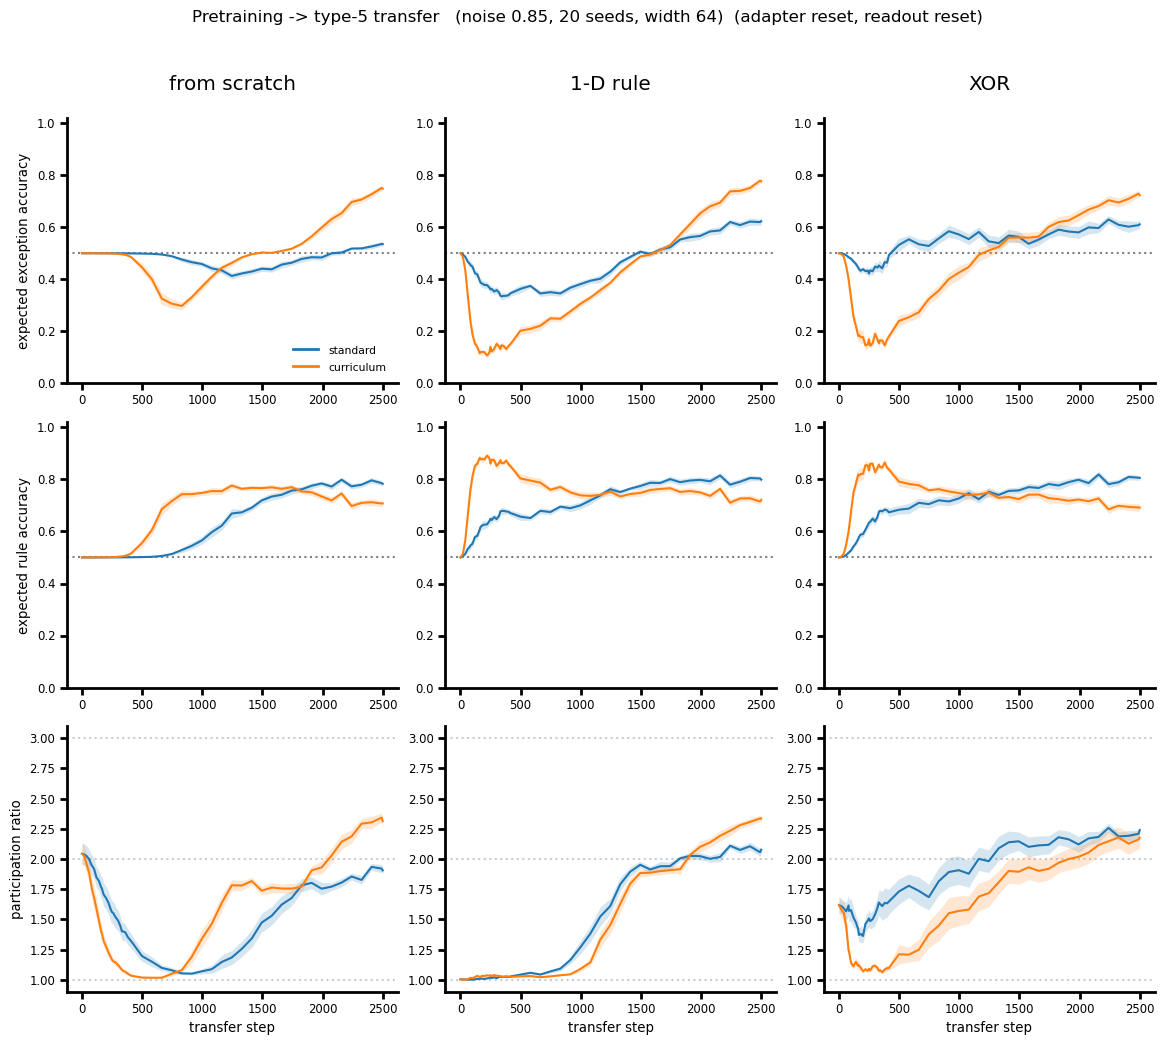

In [194]:
bp2.plot_pretrain_transfer(pt)  

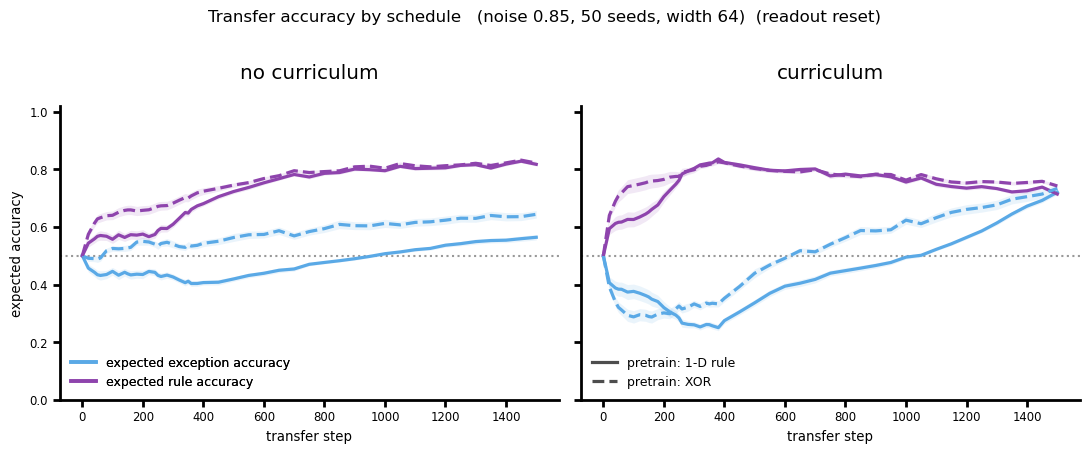

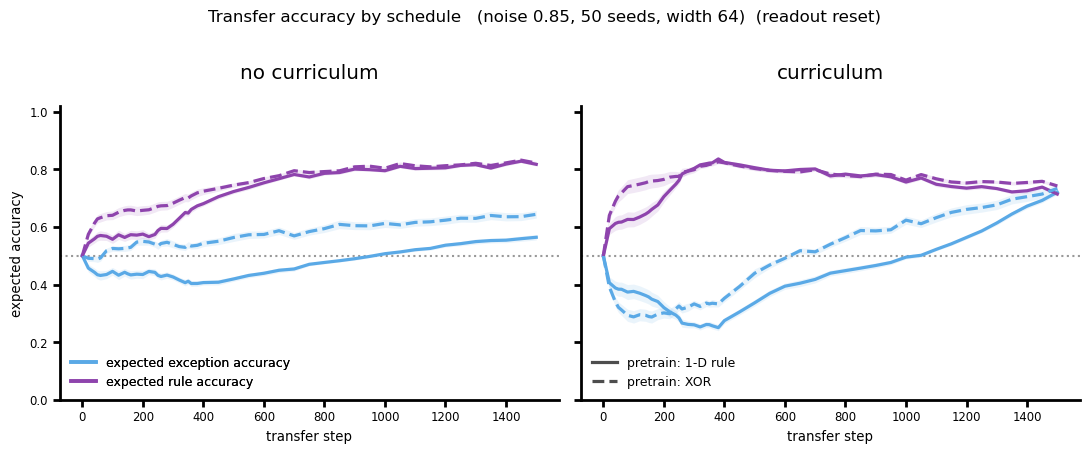

In [201]:
bp2.plot_transfer_by_schedule(pt, kinds=('1d', 'xor'))   # 2 panels; 4 lines each (blue=excep, purple=rule; solid=1d, dashed=xor)

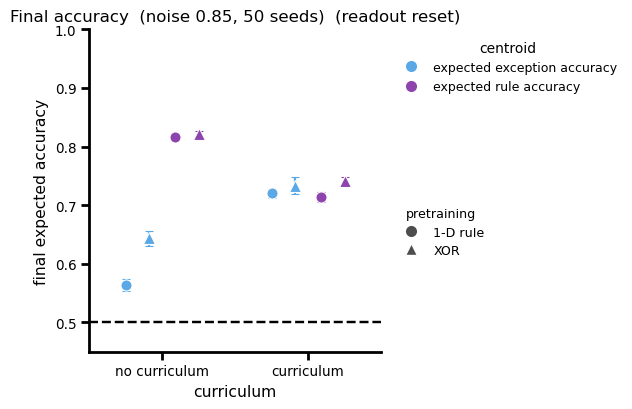

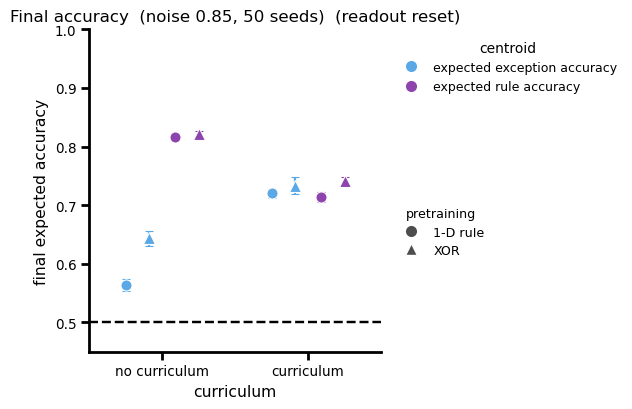

In [202]:
bp2.plot_final_accuracy_by_schedule(pt, kinds=('1d', 'xor'), ylim=(0.45, 1))   # final acc; colour=centroid type, marker=pretraining, x=curriculum